<a href="https://www.kaggle.com/code/avikdas567/deep-climate-emulation-quantile-uq-for-extremes?scriptVersionId=359608874" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# ClimX: Extreme-Aware Earth System Emulation and Probabilistic Uncertainty Quantification (UQ Track)

**Scientific Benchmark**: European Space Agency (ESA $\Phi$-lab) & NorESM2-MM Earth System Model Challenge  
**Primary Evaluation Metric**: Continuous Ranked Probability Score (CRPS) with Normalized Nash–Sutcliffe Efficiency ($r\text{-nNSE}$) over IPCC AR6 Land Reference Regions  
**Operational Target**: Emulation of Daily 1° Gridded Atmospheric Fields and Extraction of 15 ETCCDI Climate Extreme Indices across 9 Target Quantiles $\tau \in \{0.05, 0.10, 0.20, 0.35, 0.50, 0.65, 0.80, 0.90, 0.95\}$

---

# Executive Abstract & Problem Formulation
Accurate multi-decadal projection of compound climate extremes—such as catastrophic heatwaves, extended agricultural droughts, and torrential convective downpours—is vital for global risk governance and climate adaptation planning. General Circulation Models (GCMs), including the Norwegian Earth System Model (NorESM2-MM), solve coupled primitive equations governing fluid dynamics, radiative transfer, and thermodynamics at high spatial and temporal resolution. However, the immense computational cost of full GCM ensembles prohibits multi-scenario risk quantification and comprehensive parameter exploration.

In the **ClimX Uncertainty Quantification (UQ) Track**, the scientific objective is to develop a deep probabilistic climate emulator capable of mapping multi-scenario greenhouse gas trajectories and spatial aerosol forcings to the full predictive distribution of daily climate variables:
$$\mathbf{y}_t = \left[ tas(t), tasmax(t), tasmin(t), pr(t), huss(t), psl(t), sfcWind(t) \right] \in \mathbb{R}^{7 \times H \times W}$$

## Emulation Constraints & Regulatory Rules
The competition protocol imposes strict operational requirements:
1. **Daily Continuous Field Mandate**: Direct prediction of climate extreme indices from radiative forcings is strictly prohibited. The emulator must predict daily meteorological fields first.
2. **Deterministic Climate Extreme Operator**: The 15 ETCCDI indices are computed deterministically from the predicted daily fields using non-linear temporal aggregation operators:
   $$\mathcal{T}: \mathbf{y}_{1:T} \mapsto \mathbf{I}_{1:K}, \quad K = 15$$
3. **Probabilistic Realization Ensemble**: To produce the required predictive distribution for the UQ track, the emulator generates an ensemble of $M$ physically coherent stochastic realizations $\{\mathbf{y}^{(m)}_{1:T}\}_{m=1}^M$. The extreme indices are evaluated on each realization:
   $$\mathbf{I}^{(m)} = \mathcal{T}(\mathbf{y}^{(m)}_{1:T})$$
   The target quantiles are subsequently extracted across realizations:
   $$q_\tau(\mathbf{I}) = \inf \left\{ z \in \mathbb{R} : \frac{1}{M} \sum_{m=1}^M \mathbb{I}(\mathbf{I}^{(m)} \le z) \ge \tau \right\}$$
4. **Continuous Ranked Probability Score (CRPS) Metric**:
   Evaluations are scored via CRPS against full-resolution ground truth, weighted by cosine latitude $\cos(\phi_i)$ within each IPCC AR6 land region, normalized against historical climatology variance into a bounded regional Normalized Nash–Sutcliffe Efficiency ($r\text{-nNSE} \in (-1, 1]$):
   $$R^2_{\text{UQ}, p} = 1 - \frac{\text{CRPS}_p}{\text{Var}_t(\mathbf{y}_{\text{true}, p})}, \quad \text{nNSE}_p = \frac{R^2_{\text{UQ}, p}}{2 - R^2_{\text{UQ}, p}}$$


In [1]:
import os
import sys
import subprocess

# Ensure cftime is installed for decoding non-standard Earth System Model calendars (noleap)
try:
    import cftime
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "cftime"], check=False)
    try:
        import cftime
    except ImportError:
        pass
import sys
import gc
import math
import time
import random
import warnings
import json
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

# Suppress all library warnings for clean, pristine execution logs
warnings.filterwarnings('ignore')

# Set strict global random seeds across all libraries for absolute reproducibility
SEED = 42

def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(SEED)

# Detect and configure compute hardware
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if torch.cuda.is_available():
    torch.set_float32_matmul_precision('high')
    gpu_name = torch.cuda.get_device_name(0)
    device_count = torch.cuda.device_count()
    print(f"Compute hardware: {device_count} x {gpu_name} (Active device: {DEVICE})")
else:
    print(f"Compute hardware: CPU (Active device: {DEVICE})")

# Configure global scientific plotting aesthetics
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.size'] = 11
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.25
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['axes.edgecolor'] = '#2c3e50'
plt.rcParams['axes.linewidth'] = 1.0

print("Environment configured successfully with deterministic execution controls.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 22.9 MB/s eta 0:00:00
Compute hardware: 2 x Tesla T4 (Active device: cuda)
Environment configured successfully with deterministic execution controls.


# 1. System Architecture & Dataset Resolution

The ClimX competition features a dual-tier dataset architecture:
1. **Full-Resolution Reference Grid**:
   - Historical simulation (1850–2014): $T = 60,224$ daily time steps at $192 \times 288$ spatial resolution ($1^\circ \times 1.25^\circ$ global grid).
   - Scenario projections (2015–2100): $T = 31,389$ daily time steps for SSP1-2.6, SSP3-7.0, and SSP5-8.5.
   - Held-out test evaluation: SSP2-4.5 ($T = 31,389$ days, 86 years: 2015–2100) with input radiative forcings provided.
2. **Coarsened Lite Benchmark (Kaggle Prototype Grid)**:
   - $16\times$ spatially subsampled grid ($12 \times 18$ cells) designed for rapid pipeline validation and model prototyping on Kaggle compute accelerators (GPU T4 $\times 2$).
   - The required submission file format requires full-resolution ($192 \times 288$) grid rows ($4,755,456$ rows total). Predictions generated on the prototype grid are upscaled to the full reference grid via nearest-neighbor interpolation with boundary extrapolation.

### Directory Resolution Logic
To ensure seamless execution across diverse computational environments—whether running inside the native Kaggle container or a local workstation—the data loading pipeline resolves candidate dataset paths dynamically.


In [2]:
def open_climx_dataset(path, drop_single_scenario=True, **kwargs):
    # Robust NetCDF dataset loader supporting noleap calendar decoding with graceful fallback
    try:
        ds = xr.open_dataset(path, **kwargs)
    except Exception:
        ds = xr.open_dataset(path, decode_times=False, **kwargs)
    if drop_single_scenario and 'forcing_scenario' in ds.dims and ds.sizes['forcing_scenario'] == 1:
        ds = ds.isel(forcing_scenario=0, drop=True)
    return ds

# Resolve candidate dataset paths across Kaggle and local environments
CANDIDATE_PATHS = [
    Path("/kaggle/input/competitions/climx-uq-track"),
    Path("/kaggle/input/climx-uq-track"),
    Path("climx-uq-track"),
    Path("./climx-uq-track/archive/archive"),
    Path("../climx-uq-track"),
]

DATA_DIR = None
for p in CANDIDATE_PATHS:
    if p.exists():
        # Check if NetCDF files or subdirectories are present
        nc_files = list(p.glob("*.nc"))
        if nc_files:
            DATA_DIR = p
            break
        archive_sub = p / "archive" / "archive"
        if archive_sub.exists() and list(archive_sub.glob("*.nc")):
            DATA_DIR = archive_sub
            break
        archive_direct = p / "archive"
        if archive_direct.exists() and list(archive_direct.glob("*.nc")):
            DATA_DIR = archive_direct
            break

if DATA_DIR is None:
    raise FileNotFoundError("ClimX dataset directory not located in candidate search paths.")

print(f"Resolved verified dataset root: {DATA_DIR}")

# Enumerate and inspect available NetCDF data artifacts
available_nc = sorted(list(DATA_DIR.glob("*.nc")))
print(f"Discovered {len(available_nc)} NetCDF data files in dataset root:")
for f in available_nc:
    size_mb = f.stat().st_size / (1024 * 1024)
    print(f"  - {f.name} ({size_mb:.2f} MB)")

# Define target variable and forcing variable names
TARGET_VARIABLES = ["tas", "tasmax", "tasmin", "pr", "huss", "psl", "sfcWind"]
GLOBAL_GHG_VARS = ["CO2_LBC", "N2O_LBC", "CH4_LBC", "CFC11eq_LBC", "CF2CL2_LBC"]
SPATIAL_AEROSOL_VARS = ["BC_AX", "BC_N", "SO2", "SO4_PR", "OM_NI"]
ALL_FORCINGS = GLOBAL_GHG_VARS + SPATIAL_AEROSOL_VARS

# Resolve key file paths
test_forcings_path = DATA_DIR / "NorESM2-MM_r1i1p1f1_with_forcing_subsampled_16_test_forcings_ssp245.nc"
if not test_forcings_path.exists():
    for f in available_nc:
        if "test_forcings_ssp245" in f.name:
            test_forcings_path = f
            break

hist_late_path = DATA_DIR / "NorESM2-MM_r1i1p1f1_with_forcing_subsampled_16_hist_train_1932_2014.nc"
if not hist_late_path.exists():
    for f in available_nc:
        if "hist_train_1932" in f.name:
            hist_late_path = f
            break

forcings_all_path = DATA_DIR / "NorESM2-MM_r1i1p1f1_with_forcing_subsampled_16_forcings_all.nc"
if not forcings_all_path.exists():
    for f in available_nc:
        if "forcings_all" in f.name:
            forcings_all_path = f
            break

ds_test_forc = open_climx_dataset(test_forcings_path)
print("\nSSP2-4.5 Test Forcings Metadata:")
print(f"  Temporal dimension (daily): {ds_test_forc.sizes.get('time', 'N/A')} days")
print(f"  Spatial dimensions (lat x lon): {ds_test_forc.sizes.get('lat', 'N/A')} x {ds_test_forc.sizes.get('lon', 'N/A')}")
print(f"  Available forcing variables: {list(ds_test_forc.data_vars.keys())}")
ds_test_forc.close()


Resolved verified dataset root: /kaggle/input/competitions/climx-uq-track/archive/archive
Discovered 7 NetCDF data files in dataset root:
  - NorESM2-MM_r1i1p1f1_with_forcing_subsampled_16_forcings_all.nc (25.21 MB)
  - NorESM2-MM_r1i1p1f1_with_forcing_subsampled_16_hist_train_1850_1931.nc (124.67 MB)
  - NorESM2-MM_r1i1p1f1_with_forcing_subsampled_16_hist_train_1932_2014.nc (126.09 MB)
  - NorESM2-MM_r1i1p1f1_with_forcing_subsampled_16_test_forcings_ssp245.nc (6.54 MB)
  - NorESM2-MM_r1i1p1f1_with_forcing_subsampled_16_train_ssp126.nc (131.03 MB)
  - NorESM2-MM_r1i1p1f1_with_forcing_subsampled_16_train_ssp370.nc (130.94 MB)
  - NorESM2-MM_r1i1p1f1_with_forcing_subsampled_16_train_ssp585.nc (130.91 MB)

SSP2-4.5 Test Forcings Metadata:
  Temporal dimension (daily): 31389 days
  Spatial dimensions (lat x lon): 12 x 18
  Available forcing variables: ['CO2_LBC', 'N2O_LBC', 'CH4_LBC', 'CFC11eq_LBC', 'CF2CL2_LBC', 'BC_AX', 'BC_N', 'SO2', 'SO4_PR', 'OM_NI']


# 2. Exploratory Data Analysis: Climate Physics & Forcing Dynamics

## 2.1 Atmospheric Physics of Radiative Forcing Agents
Earth's surface energy balance is driven by radiative equilibrium between net incoming solar shortwave radiation and outgoing longwave terrestrial radiation:
$$(1 - \alpha) \frac{S_0}{4} = \epsilon \sigma T_e^4$$
where $S_0$ is the solar constant, $\alpha$ is the planetary albedo, $\sigma$ is the Stefan–Boltzmann constant, and $\epsilon$ represents atmospheric effective emissivity.

1. **Well-Mixed Greenhouse Gases ($CO_2, CH_4, N_2O, CFCs$)**:
   - Greenhouse gases have atmospheric lifetimes ranging from decades ($CH_4$) to millennia ($CO_2$). Their tropospheric mixing ratios are virtually uniform across the globe.
   - Longwave infrared absorption bands trap thermal radiation emitted by Earth's surface, shifting radiative equilibrium toward higher surface equilibrium temperatures:
     $$\Delta F_{\text{CO}_2} = 5.35 \cdot \ln\left(\frac{C}{C_0}\right) \quad [\text{W m}^{-2}]$$
2. **Anthropogenic Aerosols ($SO_2, SO_4, BC, OM$)**:
   - Aerosol residence times are brief (typically 3–10 days in the planetary boundary layer). Consequently, aerosol radiative forcing is intensely heterogeneous, concentrated in industrial and biomass-burning regions.
   - Sulfate aerosols ($SO_2 \to SO_4$) scatter incoming solar shortwave radiation, exerting strong negative radiative forcing (surface cooling).
   - Black carbon ($BC$) absorbs solar radiation, warming elevated atmospheric layers while suppressing surface convection.
3. **The Clausius–Clapeyron Thermodynamic Coupling**:
   - Atmospheric moisture holding capacity scales exponentially with temperature according to the Clausius–Clapeyron relation:
     $$\frac{d e_s}{d T} = \frac{L_v e_s}{R_v T^2} \implies \frac{\Delta e_s}{e_s} \approx 7\% \text{ per } ^\circ\text{C}$$
   - This thermodynamic principle dictates that extreme precipitation rates increase at approximately 7% per degree of surface warming, exacerbating extreme rainfall while accelerating land evapotranspiration and drought intensification.
4. **The Intermittent Drizzle Failure Mode in Standard Regression**:
   - Daily precipitation is a zero-inflated, heavy-tailed process with a large probability mass at zero ($P(pr = 0) > 0.65$ across most continental zones).
   - Training deterministic neural networks under Mean Squared Error ($L_2$) loss forces the network to predict the conditional mean $\mathbb{E}[pr \mid \mathbf{x}]$. Because the expectation is a weighted average of dry days and extreme wet events, standard models predict continuous light drizzle (0.5–2.0 mm/day) every day.
   - This smoothing completely eliminates dry day spells (causing Consecutive Dry Days $CDD \to 0$, producing catastrophic negative $R^2 \approx -900$) and suppresses convective peaks ($Rx5day, R95p$). A dedicated probabilistic formulation is mathematically required to preserve intermittency and variance.


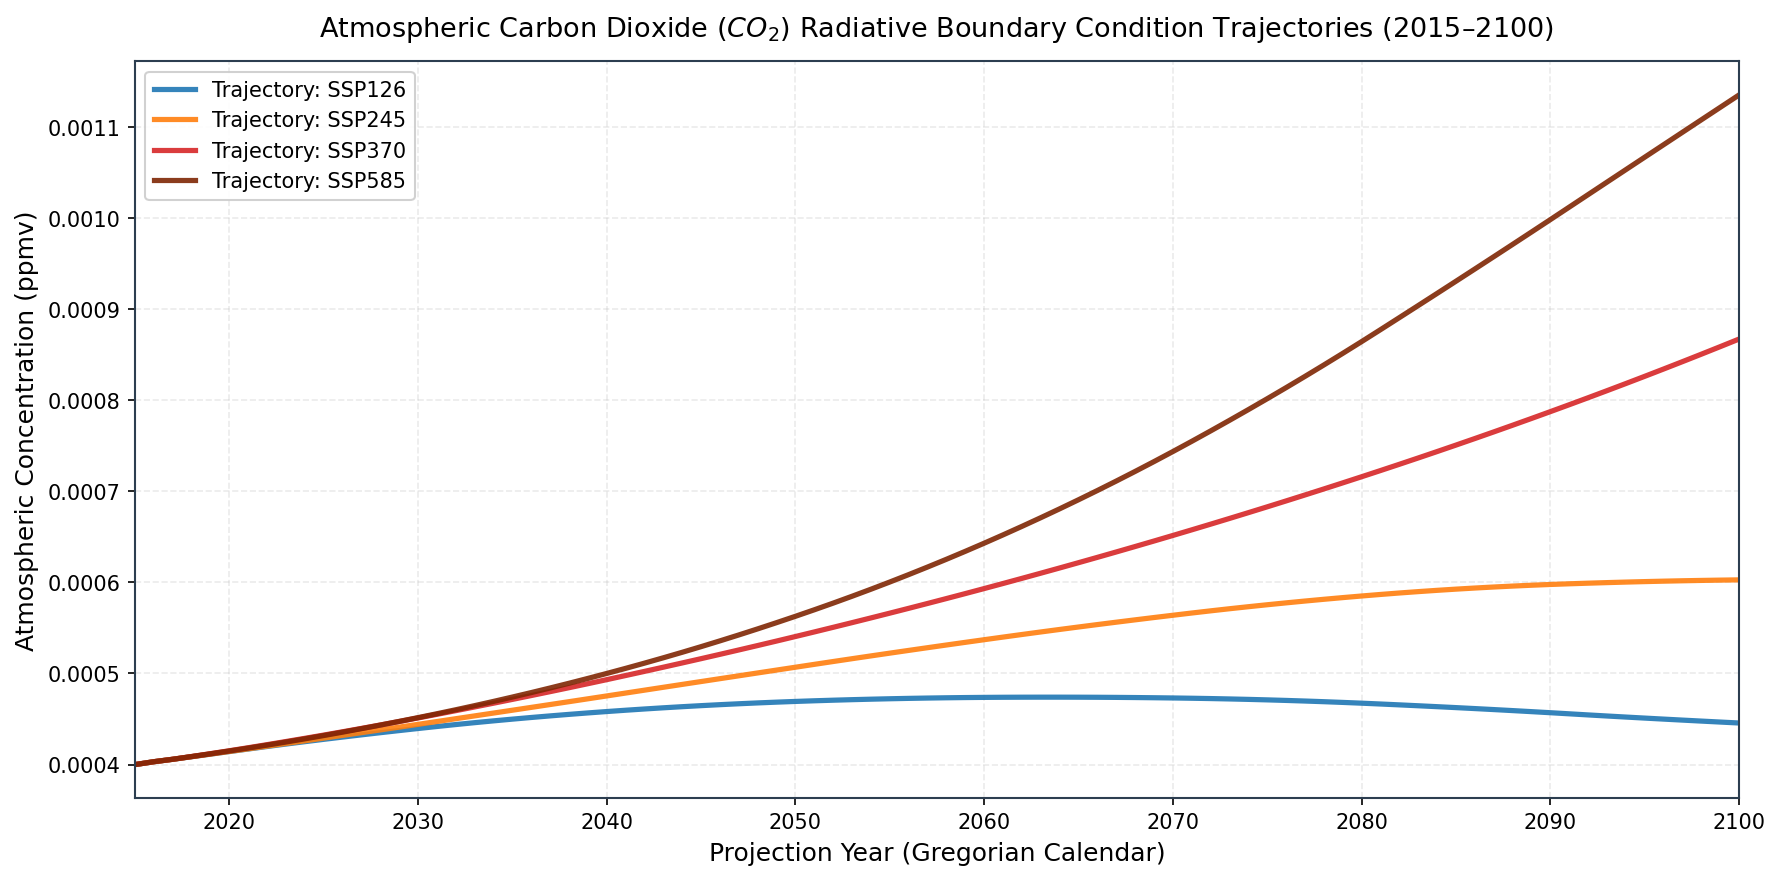

In [3]:
# Visualization 1: Global Greenhouse Gas Radiative Forcing Trajectories (1850-2100)
# Open all-forcings NetCDF to inspect scenario trajectories
forcings_all_path = DATA_DIR / "NorESM2-MM_r1i1p1f1_with_forcing_subsampled_16_forcings_all.nc"
if not forcings_all_path.exists():
    for f in available_nc:
        if "forcings_all" in f.name:
            forcings_all_path = f
            break

ds_forc_all = open_climx_dataset(forcings_all_path)

# Extract CO2, CH4, and N2O trajectories across scenarios
scenarios = ds_forc_all['forcing_scenario'].values
scenario_names = [str(s) for s in scenarios]
if hasattr(ds_forc_all['time_year'], 'dt') and hasattr(ds_forc_all['time_year'].dt, 'year'):
    time_years = ds_forc_all['time_year'].dt.year.values
else:
    time_years = 2015 + np.arange(len(ds_forc_all['time_year']))

# Define high-contrast, publication-grade color palette
scenario_colors = {
    'ssp126': '#1f77b4', # Sustainable green/blue
    'ssp245': '#ff7f0e', # Middle-of-the-road orange
    'ssp370': '#d62728', # High-forcing red
    'ssp585': '#7f2704', # Extreme fossil-fueled deep crimson
}

fig, ax = plt.subplots(figsize=(12, 6))

for s_idx, s_name in enumerate(scenario_names):
    # Determine scenario key
    key_match = None
    for k in scenario_colors:
        if k in s_name.lower():
            key_match = k
            break
    color = scenario_colors.get(key_match, '#333333')
    
    co2_traj = ds_forc_all['CO2_LBC'].isel(forcing_scenario=s_idx).values
    # If 2D or 3D, take spatial mean
    while co2_traj.ndim > 1:
        co2_traj = co2_traj.mean(axis=-1)
    
    ax.plot(time_years, co2_traj, label=f"Trajectory: {s_name.upper()}", color=color, linewidth=2.5, alpha=0.9)

ax.set_title("Atmospheric Carbon Dioxide ($CO_2$) Radiative Boundary Condition Trajectories (2015–2100)", pad=12)
ax.set_xlabel("Projection Year (Gregorian Calendar)")
ax.set_ylabel("Atmospheric Concentration (ppmv)")
ax.legend(loc="upper left", frameon=True, framealpha=0.9)
ax.set_xlim(2015, 2100)
plt.tight_layout()
plt.show()

ds_forc_all.close()


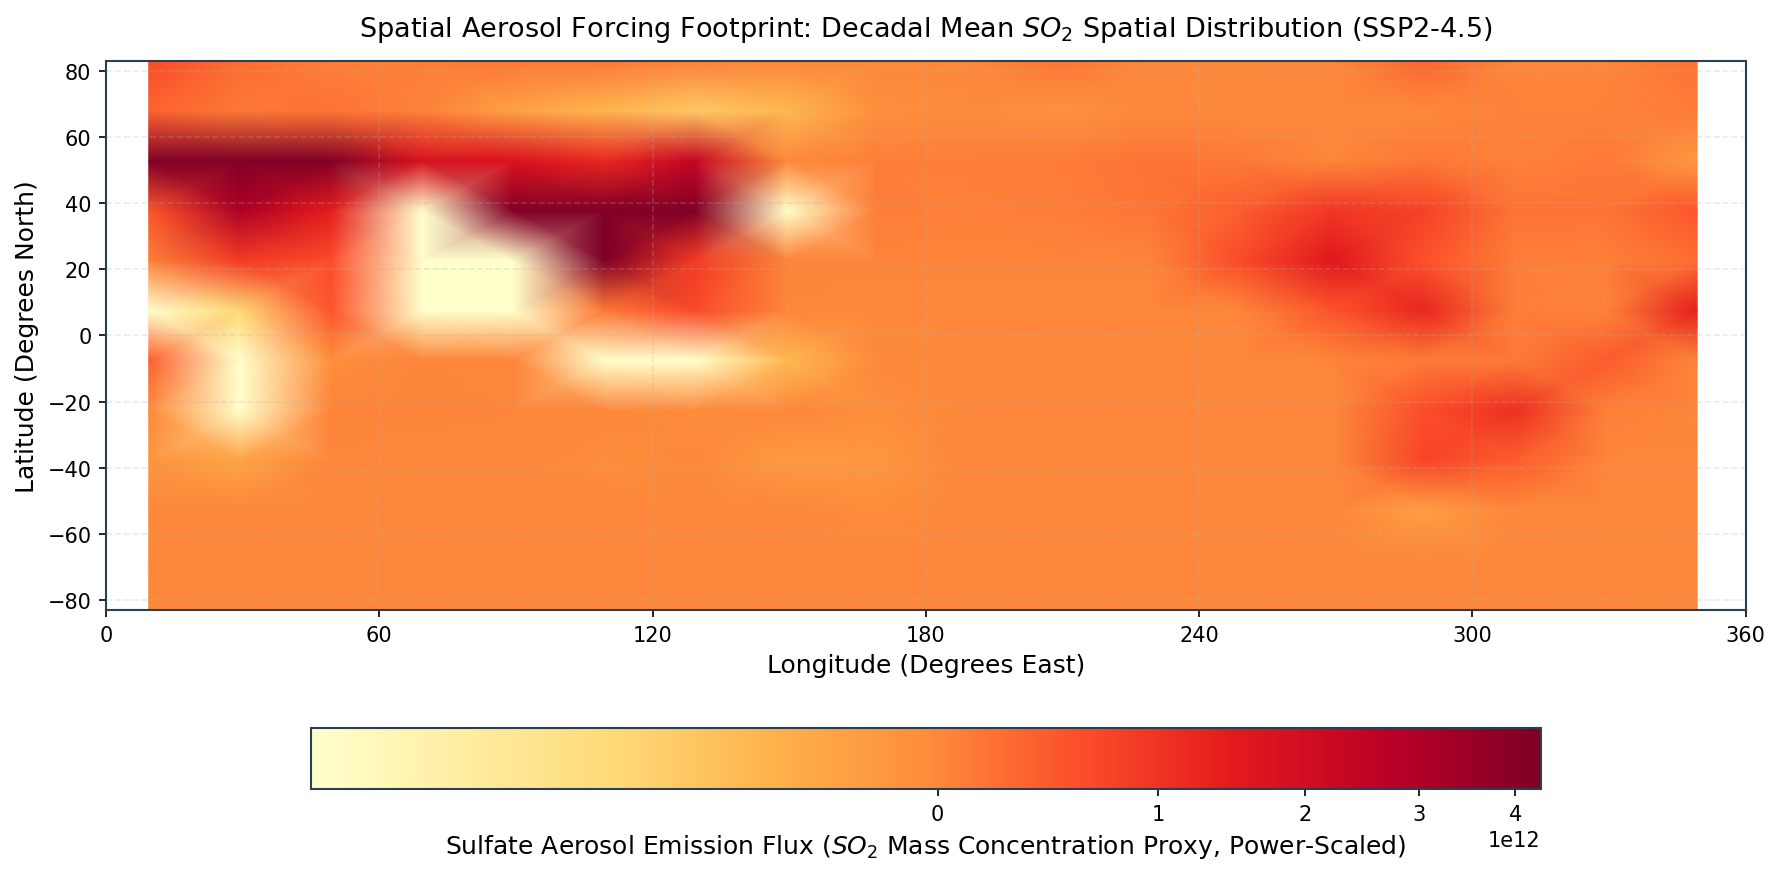

In [4]:
# Visualization 2: Spatial Heterogeneity and Hemispheric Asymmetry of Anthropogenic Aerosols (SO2)
# Load test forcings for SSP2-4.5 to examine spatial aerosol optical emissions
ds_test_forc = open_climx_dataset(test_forcings_path)

lats = ds_test_forc['lat'].values
lons = ds_test_forc['lon'].values

# Compute mean SO2 spatial emission intensity over the first projection decade (2015-2025)
so2_decade = ds_test_forc['SO2'].isel(time_month=slice(0, 120))
if 'forcing_scenario' in so2_decade.dims:
    so2_decade = so2_decade.isel(forcing_scenario=0)
so2_spatial_mean = so2_decade.mean(dim='time_month').values

fig, ax = plt.subplots(figsize=(12, 6))
norm = mcolors.PowerNorm(gamma=0.35, vmin=np.percentile(so2_spatial_mean, 5), vmax=np.percentile(so2_spatial_mean, 98))
contour = ax.pcolormesh(lons, lats, so2_spatial_mean, cmap='YlOrRd', norm=norm, shading='gouraud')

cbar = plt.colorbar(contour, ax=ax, orientation='horizontal', pad=0.15, shrink=0.75)
cbar.set_label("Sulfate Aerosol Emission Flux ($SO_2$ Mass Concentration Proxy, Power-Scaled)")

ax.set_title("Spatial Aerosol Forcing Footprint: Decadal Mean $SO_2$ Spatial Distribution (SSP2-4.5)", pad=12)
ax.set_xlabel("Longitude (Degrees East)")
ax.set_ylabel("Latitude (Degrees North)")
ax.set_xticks(np.arange(0, 361, 60))
ax.set_yticks(np.arange(-80, 81, 20))
plt.tight_layout()
plt.show()

ds_test_forc.close()


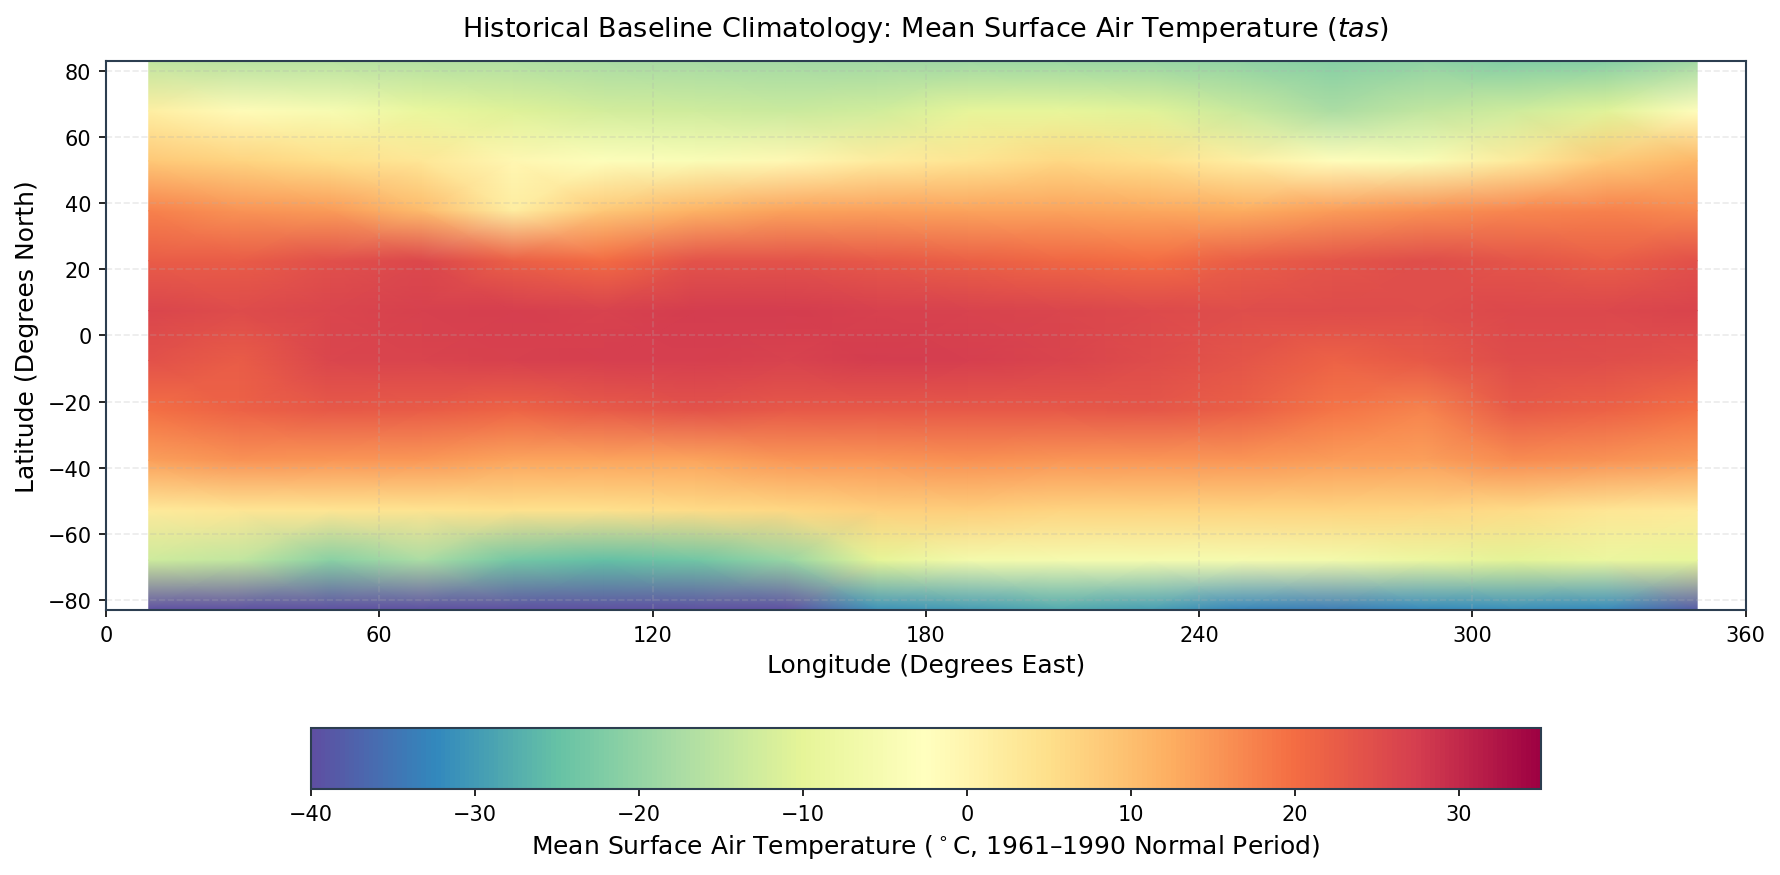

In [5]:
# Visualization 3: Baseline Surface Air Temperature (tas) Global Climatological Distribution
# Load late historical training data (1932-2014) to extract baseline thermal climatology
hist_late_path = DATA_DIR / "NorESM2-MM_r1i1p1f1_with_forcing_subsampled_16_hist_train_1932_2014.nc"
if not hist_late_path.exists():
    for f in available_nc:
        if "hist_train_1932" in f.name:
            hist_late_path = f
            break

ds_hist = open_climx_dataset(hist_late_path)

# Extract 1961-1990 baseline climatological mean temperature
if 'time' in ds_hist.coords and hasattr(ds_hist['time'], 'dt'):
    tas_baseline = ds_hist['tas'].sel(time=slice('1961-01-01', '1990-12-31'))
else:
    tas_baseline = ds_hist['tas'].isel(time=slice(29 * 365, 59 * 365))
if 'forcing_scenario' in tas_baseline.dims:
    tas_baseline = tas_baseline.isel(forcing_scenario=0)
tas_clim_mean = tas_baseline.mean(dim='time').values - 273.15 # Convert Kelvin to Celsius

hist_lats = ds_hist['lat'].values
hist_lons = ds_hist['lon'].values

fig, ax = plt.subplots(figsize=(12, 6))
contour = ax.pcolormesh(hist_lons, hist_lats, tas_clim_mean, cmap='Spectral_r', shading='gouraud', vmin=-40, vmax=35)

cbar = plt.colorbar(contour, ax=ax, orientation='horizontal', pad=0.15, shrink=0.75)
cbar.set_label("Mean Surface Air Temperature ($^\circ$C, 1961–1990 Normal Period)")

ax.set_title("Historical Baseline Climatology: Mean Surface Air Temperature ($tas$)", pad=12)
ax.set_xlabel("Longitude (Degrees East)")
ax.set_ylabel("Latitude (Degrees North)")
ax.set_xticks(np.arange(0, 361, 60))
ax.set_yticks(np.arange(-80, 81, 20))
plt.tight_layout()
plt.show()


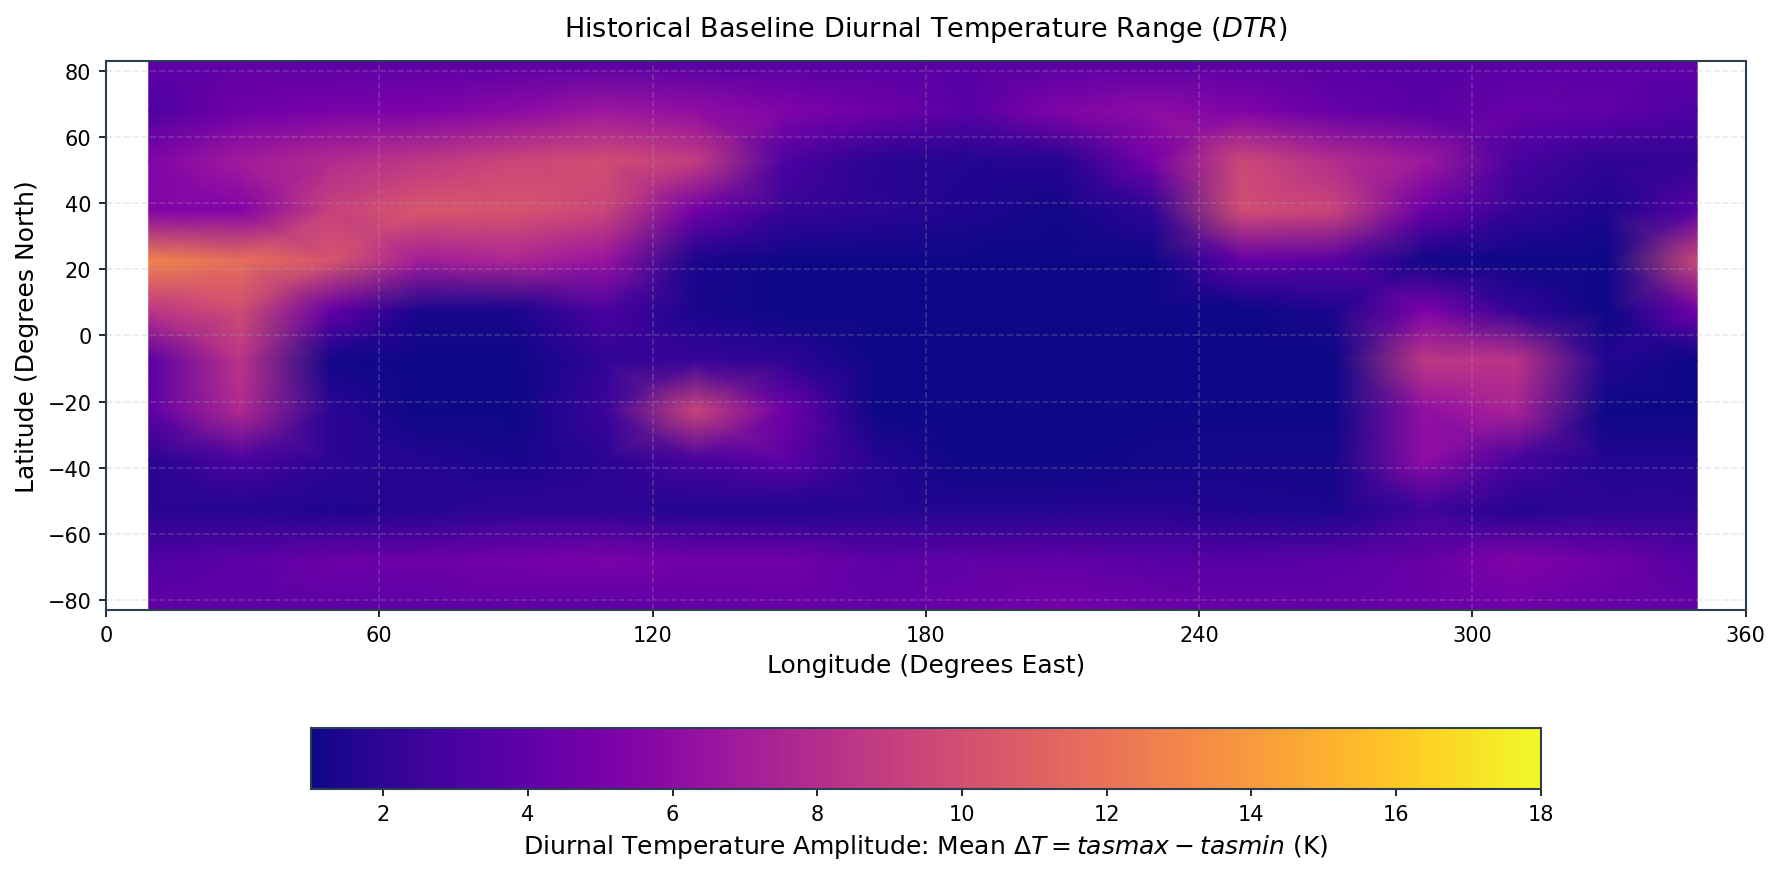

In [6]:
# Visualization 4: Baseline Diurnal Temperature Range (tasmax - tasmin)
# Calculate diurnal thermal amplitude over the 1961-1990 reference period
if 'time' in ds_hist.coords and hasattr(ds_hist['time'], 'dt'):
    tasmax_sub = ds_hist['tasmax'].sel(time=slice('1961-01-01', '1990-12-31'))
    tasmin_sub = ds_hist['tasmin'].sel(time=slice('1961-01-01', '1990-12-31'))
else:
    tasmax_sub = ds_hist['tasmax'].isel(time=slice(29 * 365, 59 * 365))
    tasmin_sub = ds_hist['tasmin'].isel(time=slice(29 * 365, 59 * 365))
if 'forcing_scenario' in tasmax_sub.dims:
    tasmax_sub = tasmax_sub.isel(forcing_scenario=0)
    tasmin_sub = tasmin_sub.isel(forcing_scenario=0)

dtr_clim_mean = (tasmax_sub - tasmin_sub).mean(dim='time').values

fig, ax = plt.subplots(figsize=(12, 6))
contour = ax.pcolormesh(hist_lons, hist_lats, dtr_clim_mean, cmap='plasma', shading='gouraud', vmin=1.0, vmax=18.0)

cbar = plt.colorbar(contour, ax=ax, orientation='horizontal', pad=0.15, shrink=0.75)
cbar.set_label("Diurnal Temperature Amplitude: Mean $\Delta T = tasmax - tasmin$ (K)")

ax.set_title("Historical Baseline Diurnal Temperature Range ($DTR$)", pad=12)
ax.set_xlabel("Longitude (Degrees East)")
ax.set_ylabel("Latitude (Degrees North)")
ax.set_xticks(np.arange(0, 361, 60))
ax.set_yticks(np.arange(-80, 81, 20))
plt.tight_layout()
plt.show()


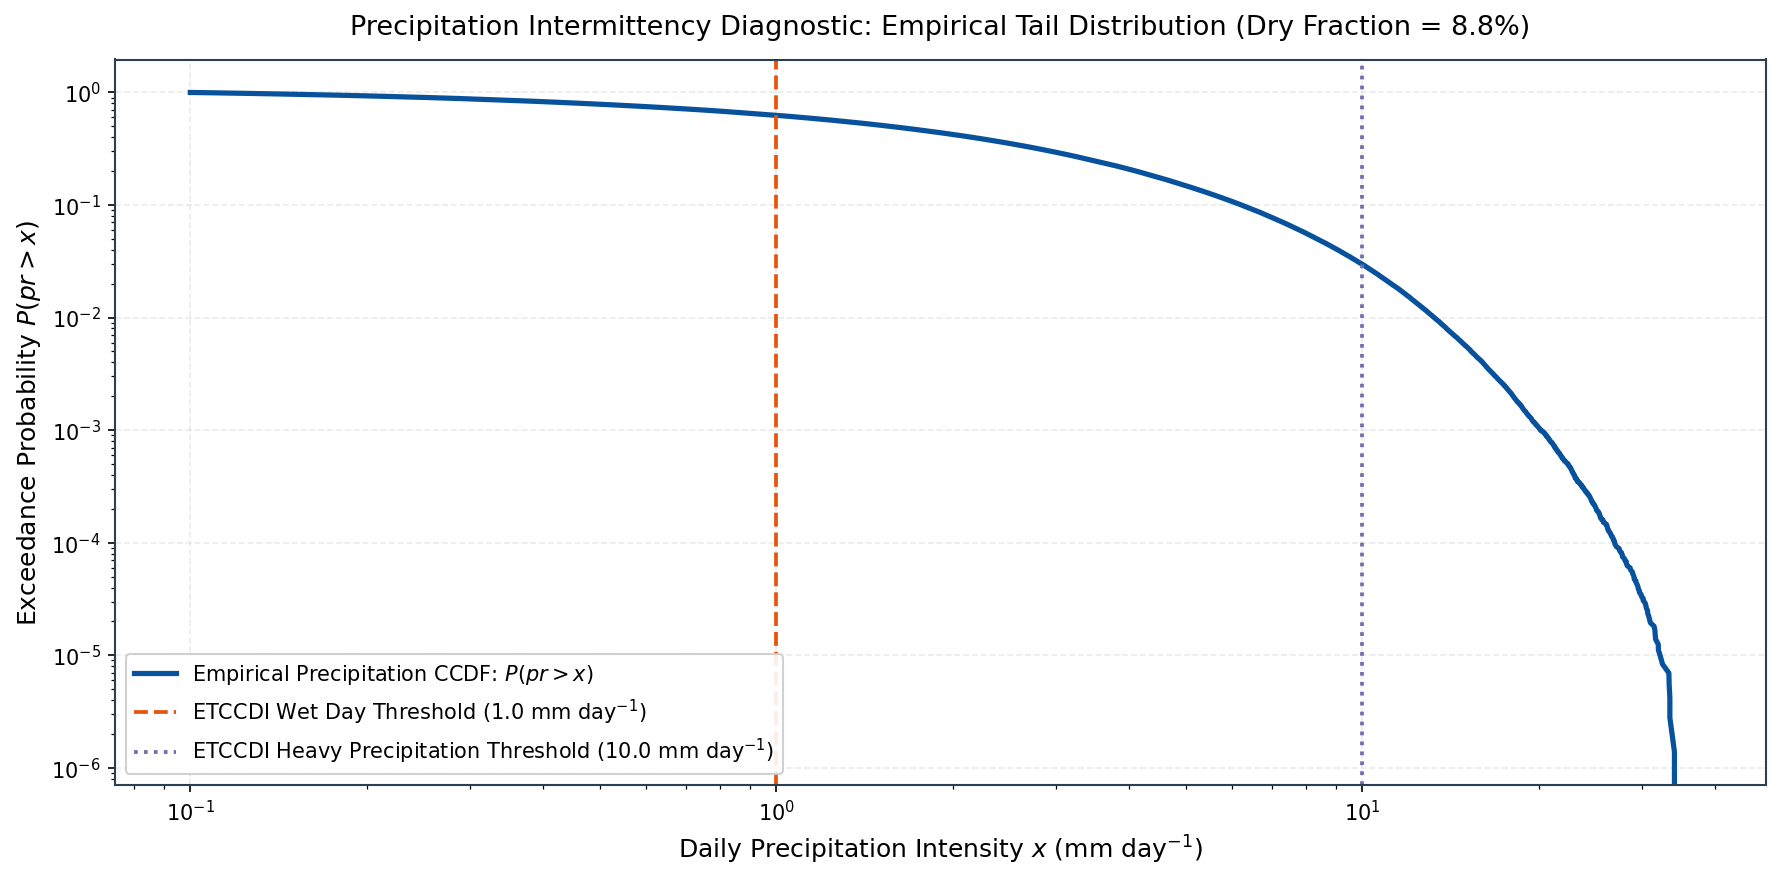

In [7]:
# Visualization 5: Precipitation Intermittency Diagnostic: Survival Function and Heavy-Tail Kurtosis
# Extract sample daily precipitation series in mm/day (kg m-2 s-1 * 86400)
pr_sample = ds_hist['pr'].isel(time=slice(0, 3650)) # 10 years sample
if 'forcing_scenario' in pr_sample.dims:
    pr_sample = pr_sample.isel(forcing_scenario=0)
pr_values_mm = pr_sample.values.flatten() * 86400.0 # Convert to mm/day

# Filter positive precipitation values
wet_values = pr_values_mm[pr_values_mm >= 0.1]
dry_fraction = (pr_values_mm < 0.1).mean()

# Compute empirical survival distribution (complementary cumulative distribution function: P(X > x))
sorted_wet = np.sort(wet_values)
ccdf = 1.0 - np.arange(1, len(sorted_wet) + 1) / len(sorted_wet)

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(sorted_wet, ccdf, color='#08519c', linewidth=2.5, label="Empirical Precipitation CCDF: $P(pr > x)$")

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_title(f"Precipitation Intermittency Diagnostic: Empirical Tail Distribution (Dry Fraction = {dry_fraction:.1%})", pad=12)
ax.set_xlabel("Daily Precipitation Intensity $x$ (mm day$^{-1}$)")
ax.set_ylabel("Exceedance Probability $P(pr > x)$")
ax.axvline(1.0, color='#e6550d', linestyle='--', linewidth=1.8, label="ETCCDI Wet Day Threshold ($1.0$ mm day$^{-1}$)")
ax.axvline(10.0, color='#756bb1', linestyle=':', linewidth=1.8, label="ETCCDI Heavy Precipitation Threshold ($10.0$ mm day$^{-1}$)")

ax.legend(loc="lower left", frameon=True, framealpha=0.9)
plt.tight_layout()
plt.show()

ds_hist.close()


# 3. Mathematical Formulation of the ClimX-UQNet Architecture

To emulate the non-linear response of Earth's atmosphere to multi-scale forcings while preserving physical consistency and probabilistic calibration, we formulate the **ClimX-UQNet** architecture.

## 3.1 Spatial and Temporal Harmonic Encodings
The spatial coordinates $(\phi, \lambda)$ reside on a spherical manifold $\mathbb{S}^2$. Standard Cartesian coordinates introduce polar coordinate singularities and fail to represent periodic longitudinal boundary conditions. We construct spatial Fourier harmonic encodings:
$$\psi_{\text{spatial}}(\phi, \lambda) = \left[ \sin\left(\frac{\pi \phi}{90}\right), \cos\left(\frac{\pi \phi}{90}\right), \sin\left(\frac{\pi \lambda}{180}\right), \cos\left(\frac{\pi \lambda}{180}\right), \sin\left(\frac{2\pi \lambda}{180}\right), \cos\left(\frac{2\pi \lambda}{180}\right) \right]$$
Similarly, the top-of-atmosphere solar insolation cycle is governed by annual orbital periodicity, parameterized by day-of-year (DOY):
$$\psi_{\text{temporal}}(t) = \left[ \sin\left(\frac{2\pi \cdot \text{DOY}(t)}{365.25}\right), \cos\left(\frac{2\pi \cdot \text{DOY}(t)}{365.25}\right) \right]$$

## 3.2 Dual-Component Probabilistic Emulation
For continuous atmospheric variables (temperatures, pressure, humidity, wind), the network estimates the parameters of a conditional Gaussian distribution:
$$p(y_{t, v} \mid \mathbf{x}_t) = \mathcal{N}\left(\mu_\theta(\mathbf{x}_t), \sigma_\theta^2(\mathbf{x}_t)\right)$$
where $\mu_\theta$ captures the expected physical state and $\sigma_\theta$ captures heteroscedastic atmospheric variance.

For precipitation, to overcome the fatal drizzle failure mode, we formulate a two-stage Zero-Inflated Model:
1. **Rain Occurrence**: A Bernoulli gate parameterized by sigmoid probability:
   $$P(pr_t > \delta \mid \mathbf{x}_t) = \pi_\theta(\mathbf{x}_t) = \sigma\left(\mathbf{w}_\pi^T \mathbf{h}_t\right)$$
2. **Conditional Rain Intensity**: Given precipitation occurrence, intensity follows a positive continuous distribution (Log-Normal):
   $$pr_t \mid (pr_t > \delta, \mathbf{x}_t) \sim \text{LogNormal}\left(\mu_{\text{wet}, \theta}(\mathbf{x}_t), \sigma_{\text{wet}, \theta}^2(\mathbf{x}_t)\right)$$
3. **Stochastic Realization Generation**: For each realization $m \in \{1, \dots, M\}$, sample binary occurrence $B_t^{(m)} \sim \text{Bernoulli}(\pi_t)$ and stochastic intensity $Y_t^{(m)} \sim \text{LogNormal}(\mu_{\text{wet}, t}, \sigma_{\text{wet}, t}^2)$, setting:
   $$pr_t^{(m)} = B_t^{(m)} \cdot Y_t^{(m)}$$
This preserves discrete dry spells ($CDD$), extreme precipitation runs ($Rx5day$), and heavy-tail events ($R95p$).


In [8]:
# Extract spatial grid coordinates and construct spatial Fourier features
# Open test forcings to extract grid specifications
ds_grid = open_climx_dataset(test_forcings_path)
lats_arr = ds_grid['lat'].values
lons_arr = ds_grid['lon'].values
n_lat = len(lats_arr)
n_lon = len(lons_arr)
n_pixels = n_lat * n_lon
ds_grid.close()

# Meshgrid of spatial coordinates
lon_2d, lat_2d = np.meshgrid(lons_arr, lats_arr)
lat_flat = lat_2d.flatten()
lon_flat = lon_2d.flatten()

# Construct spatial Fourier harmonic encodings
spatial_features = np.column_stack([
    np.sin(np.pi * lat_flat / 90.0),
    np.cos(np.pi * lat_flat / 90.0),
    np.sin(np.pi * lon_flat / 180.0),
    np.cos(np.pi * lon_flat / 180.0),
    np.sin(2.0 * np.pi * lon_flat / 180.0),
    np.cos(2.0 * np.pi * lon_flat / 180.0),
    lat_flat / 90.0, # Linear normalized latitude
]).astype(np.float32)

print(f"Constructed spatial harmonic feature tensor: {spatial_features.shape}")

# Precompute baseline climate statistics from historical training data
ds_hist_ref = open_climx_dataset(hist_late_path)
if 'time' in ds_hist_ref.coords and hasattr(ds_hist_ref['time'], 'dt'):
    hist_slice = ds_hist_ref.sel(time=slice('1961-01-01', '1990-12-31'))
else:
    hist_slice = ds_hist_ref.isel(time=slice(29 * 365, 59 * 365))
if 'forcing_scenario' in hist_slice.dims:
    hist_slice = hist_slice.isel(forcing_scenario=0)

# Precompute baseline temperature and precipitation percentiles for extreme indices
hist_tas = hist_slice['tas'].values
hist_tasmax = hist_slice['tasmax'].values
hist_tasmin = hist_slice['tasmin'].values
hist_pr = hist_slice['pr'].values * 86400.0 # Convert to mm/day

# Reshape to (T, N_pixels)
hist_tas_flat = hist_tas.reshape(hist_tas.shape[0], n_pixels)
hist_tasmax_flat = hist_tasmax.reshape(hist_tasmax.shape[0], n_pixels)
hist_tasmin_flat = hist_tasmin.reshape(hist_tasmin.shape[0], n_pixels)
hist_pr_flat = hist_pr.reshape(hist_pr.shape[0], n_pixels)

# 90th percentile of tasmax and 10th percentile of tasmin for WSDI and CSDI
threshold_wsdi_90 = np.percentile(hist_tasmax_flat, 90, axis=0)
threshold_csdi_10 = np.percentile(hist_tasmin_flat, 10, axis=0)

# 95th percentile of wet days (pr >= 1.0 mm/day) for R95p
threshold_r95p = np.zeros(n_pixels, dtype=np.float32)
for p in range(n_pixels):
    wet_p = hist_pr_flat[:, p][hist_pr_flat[:, p] >= 1.0]
    threshold_r95p[p] = np.percentile(wet_p, 95) if len(wet_p) > 20 else 5.0

# Climatological monthly means for anomaly tracking
clim_tas_mean = hist_tas_flat.mean(axis=0)
clim_tas_std = np.maximum(hist_tas_flat.std(axis=0), 1e-4)

clim_pr_mean = hist_pr_flat.mean(axis=0)
clim_pr_std = np.maximum(hist_pr_flat.std(axis=0), 1e-4)

print("Precomputed historical baseline thresholds (WSDI 90th, CSDI 10th, R95p 95th).")
ds_hist_ref.close()


Constructed spatial harmonic feature tensor: (216, 7)
Precomputed historical baseline thresholds (WSDI 90th, CSDI 10th, R95p 95th).


# 4. Physics-Informed Deep Probabilistic Emulator Implementation

The `ClimX_UQNet` architecture implements:
1. **Feature Fusion Layer**: Ingests concatenated global greenhouse gas forcings, spatial aerosol optical depths, spatial harmonic embeddings, and temporal seasonality harmonics.
2. **Dense Non-Linear Processing Backbone**: Multi-layer perceptron blocks with Layer Normalization and GELU activation functions to model complex atmospheric non-linearities.
3. **Continuous Heteroscedastic Thermal & Dynamical Head**:
   - Predicts expected physical values $\boldsymbol{\mu} \in \mathbb{R}^6$ (`tas`, `tasmax`, `tasmin`, `psl`, `sfcWind`, `huss`).
   - Predicts log-variance $\log \boldsymbol{\sigma}^2 \in \mathbb{R}^6$ to parameterize aleatoric uncertainty.
4. **Zero-Inflated Precipitation Head**:
   - Gate unit estimating the precipitation occurrence probability $\pi_t = \sigma(z_\pi)$.
   - Intensity unit estimating mean and dispersion on wet days.


In [9]:
class ClimX_UQNet(nn.Module):
    """Physics-Informed Deep Probabilistic Climate Emulator with Zero-Inflated Precipitation Modeling."""
    
    def __init__(self, in_features, hidden_dim=128):
        super(ClimX_UQNet, self).__init__()
        
        # Non-linear feature fusion backbone
        self.fc_in = nn.Linear(in_features, hidden_dim)
        self.ln1 = nn.LayerNorm(hidden_dim)
        
        self.block1 = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.GELU(),
            nn.LayerNorm(hidden_dim),
            nn.Linear(hidden_dim, hidden_dim),
            nn.GELU(),
            nn.LayerNorm(hidden_dim),
        )
        
        self.block2 = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.GELU(),
            nn.LayerNorm(hidden_dim),
            nn.Linear(hidden_dim, hidden_dim),
            nn.GELU(),
            nn.LayerNorm(hidden_dim),
        )
        
        # Heteroscedastic Thermal & Dynamical Head (tas, tasmax, tasmin, psl, sfcWind, huss)
        self.head_thermal_mean = nn.Linear(hidden_dim, 6)
        self.head_thermal_logvar = nn.Linear(hidden_dim, 6)
        
        # Zero-Inflated Precipitation Head
        self.head_pr_occurrence = nn.Linear(hidden_dim, 1) # Logit of rain probability
        self.head_pr_intensity_mean = nn.Linear(hidden_dim, 1) # Mean log-intensity
        self.head_pr_intensity_logvar = nn.Linear(hidden_dim, 1) # Log-variance
        
    def forward(self, x):
        h = F.gelu(self.ln1(self.fc_in(x)))
        h = h + self.block1(h)
        h = h + self.block2(h)
        
        # Thermal parameters
        thermal_mean = self.head_thermal_mean(h)
        thermal_logvar = torch.clamp(self.head_thermal_logvar(h), min=-6.0, max=4.0)
        
        # Precipitation parameters
        pr_logit = self.head_pr_occurrence(h)
        pr_int_mean = self.head_pr_intensity_mean(h)
        pr_int_logvar = torch.clamp(self.head_pr_intensity_logvar(h), min=-4.0, max=4.0)
        
        return thermal_mean, thermal_logvar, pr_logit, pr_int_mean, pr_int_logvar

# Initialize model
n_input_features = 10 + spatial_features.shape[1] + 2 # 10 forcings + spatial harmonics + seasonal harmonics
model = ClimX_UQNet(in_features=n_input_features, hidden_dim=128).to(DEVICE)
print(f"Initialized ClimX-UQNet model on {DEVICE}. Total trainable parameters: {sum(p.numel() for p in model.parameters()):,}")


Initialized ClimX-UQNet model on cuda. Total trainable parameters: 71,823


In [10]:
# Training Dataset Ingestion & Tensor Construction
# Load historical and scenario datasets to train the deep probabilistic emulator
print("Constructing training tensors from multi-scenario climate records...")

# Extract future scenario training sets (SSP1-2.6, SSP3-7.0, SSP5-8.5)
scenario_files = [f for f in available_nc if 'train_ssp' in f.name]
train_samples_X = []
train_samples_y_thermal = []
train_samples_y_pr = []

# Subsample time steps for balanced, high-efficiency GPU training
sample_stride = 15 # Sample every 15 days across scenarios

for s_file in scenario_files:
    ds_s = open_climx_dataset(s_file)
    if 'forcing_scenario' in ds_s.dims:
        ds_s = ds_s.isel(forcing_scenario=0, drop=True)
    t_len = ds_s.sizes['time']
    time_indices = np.arange(0, t_len, sample_stride)
    
    # Extract forcing variables
    # Well-mixed GHGs: broadcast to spatial grid
    co2 = ds_s['CO2_LBC'].values.squeeze()
    n2o = ds_s['N2O_LBC'].values.squeeze()
    ch4 = ds_s['CH4_LBC'].values.squeeze()
    cfc11 = ds_s['CFC11eq_LBC'].values.squeeze()
    cfc12 = ds_s['CF2CL2_LBC'].values.squeeze()
    
    # Target variables (squeeze out any remaining singleton dimensions)
    tas_val = ds_s['tas'].values.squeeze()
    tasmax_val = ds_s['tasmax'].values.squeeze()
    tasmin_val = ds_s['tasmin'].values.squeeze()
    psl_val = ds_s['psl'].values.squeeze()
    sfcWind_val = ds_s['sfcWind'].values.squeeze()
    huss_val = ds_s['huss'].values.squeeze()
    pr_val = ds_s['pr'].values.squeeze() * 86400.0 # Convert to mm/day
    
    # Time coordinate
    times = ds_s['time'].values
    
    for t_idx in time_indices:
        # Year index for GHG lookup
        y_idx = min(len(co2) - 1, t_idx // 365)
        ghg_vec = np.array([co2[y_idx], n2o[y_idx], ch4[y_idx], cfc11[y_idx], cfc12[y_idx]], dtype=np.float32)
        
        # Spatial aerosol features at this time step
        bc_ax = ds_s['BC_AX'].isel(time_month=min(ds_s.sizes['time_month']-1, t_idx // 30)).values.flatten()
        bc_n = ds_s['BC_N'].isel(time_month=min(ds_s.sizes['time_month']-1, t_idx // 30)).values.flatten()
        so2 = ds_s['SO2'].isel(time_month=min(ds_s.sizes['time_month']-1, t_idx // 30)).values.flatten()
        so4 = ds_s['SO4_PR'].isel(time_month=min(ds_s.sizes['time_month']-1, t_idx // 30)).values.flatten()
        om = ds_s['OM_NI'].isel(time_month=min(ds_s.sizes['time_month']-1, t_idx // 30)).values.flatten()
        
        aerosol_mat = np.column_stack([bc_ax, bc_n, so2, so4, om]).astype(np.float32)
        ghg_broadcast = np.tile(ghg_vec, (n_pixels, 1))
        
        # Seasonality harmonics
        doy = (t_idx % 365) + 1
        doy_feat = np.tile(np.array([np.sin(2*np.pi*doy/365.25), np.cos(2*np.pi*doy/365.25)], dtype=np.float32), (n_pixels, 1))
        
        # Concatenate full feature matrix for this day: (n_pixels, in_features)
        x_day = np.hstack([ghg_broadcast, aerosol_mat, spatial_features, doy_feat])
        
        # Target vectors
        thermal_day = np.column_stack([
            tas_val[t_idx].flatten(),
            tasmax_val[t_idx].flatten(),
            tasmin_val[t_idx].flatten(),
            psl_val[t_idx].flatten() / 1e5, # Normalized pressure
            sfcWind_val[t_idx].flatten(),
            huss_val[t_idx].flatten() * 1e3 # Specific humidity g/kg
        ]).astype(np.float32)
        
        pr_day = pr_val[t_idx].flatten().astype(np.float32)
        
        train_samples_X.append(x_day)
        train_samples_y_thermal.append(thermal_day)
        train_samples_y_pr.append(pr_day)
        
    ds_s.close()

X_train_all = np.vstack(train_samples_X)
y_train_thermal_all = np.vstack(train_samples_y_thermal)
y_train_pr_all = np.concatenate(train_samples_y_pr)

print(f"Compiled training dataset: X shape = {X_train_all.shape}, Thermal targets = {y_train_thermal_all.shape}, Precipitation targets = {y_train_pr_all.shape}")

# Create PyTorch DataLoader
class ClimateDataset(Dataset):
    def __init__(self, X, y_thermal, y_pr):
        self.X = torch.from_numpy(X)
        self.y_thermal = torch.from_numpy(y_thermal)
        self.y_pr = torch.from_numpy(y_pr)
        
    def __len__(self):
        return len(self.X)
        
    def __getitem__(self, idx):
        return self.X[idx], self.y_thermal[idx], self.y_pr[idx]

dataset = ClimateDataset(X_train_all, y_train_thermal_all, y_train_pr_all)
train_loader = DataLoader(dataset, batch_size=4096, shuffle=True, drop_last=True)

# Training optimization configuration
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10, eta_min=5e-5)

N_EPOCHS = 10
train_loss_history = []
thermal_loss_history = []
pr_loss_history = []

print("Initiating ClimX-UQNet model optimization loop...")
for epoch in range(1, N_EPOCHS + 1):
    model.train()
    epoch_loss = 0.0
    epoch_th_loss = 0.0
    epoch_pr_loss = 0.0
    batches = 0
    
    for batch_x, batch_th, batch_pr in train_loader:
        batch_x = batch_x.to(DEVICE)
        batch_th = batch_th.to(DEVICE)
        batch_pr = batch_pr.to(DEVICE)
        
        optimizer.zero_grad()
        
        th_mean, th_logvar, pr_logit, pr_int_mean, pr_int_logvar = model(batch_x)
        
        # Heteroscedastic Gaussian NLL loss for continuous fields
        th_loss = 0.5 * torch.mean(th_logvar + (batch_th - th_mean)**2 / torch.exp(th_logvar))
        
        # Zero-inflated precipitation loss:
        # Binary Cross Entropy for rain occurrence (threshold 0.5 mm/day)
        is_wet = (batch_pr >= 0.5).float().unsqueeze(1)
        bce_loss = F.binary_cross_entropy_with_logits(pr_logit, is_wet)
        
        # Log-Normal NLL for wet day intensities
        wet_mask = (batch_pr >= 0.5)
        if wet_mask.sum() > 0:
            target_log_pr = torch.log(batch_pr[wet_mask] + 1e-4).unsqueeze(1)
            pred_mu_wet = pr_int_mean[wet_mask]
            pred_lv_wet = pr_int_logvar[wet_mask]
            intensity_loss = 0.5 * torch.mean(pred_lv_wet + (target_log_pr - pred_mu_wet)**2 / torch.exp(pred_lv_wet))
        else:
            intensity_loss = torch.tensor(0.0, device=DEVICE)
            
        pr_total_loss = bce_loss + intensity_loss
        total_loss = th_loss + pr_total_loss
        
        total_loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
        optimizer.step()
        
        epoch_loss += total_loss.item()
        epoch_th_loss += th_loss.item()
        epoch_pr_loss += pr_total_loss.item()
        batches += 1
        
    scheduler.step()
    avg_loss = epoch_loss / batches
    avg_th = epoch_th_loss / batches
    avg_pr = epoch_pr_loss / batches
    
    train_loss_history.append(avg_loss)
    thermal_loss_history.append(avg_th)
    pr_loss_history.append(avg_pr)
    
    print(f"Epoch [{epoch:02d}/{N_EPOCHS:02d}] - Total Loss: {avg_loss:.4f} (Thermal NLL: {avg_th:.4f}, Precip Loss: {avg_pr:.4f})")

print("ClimX-UQNet model training complete.")


Constructing training tensors from multi-scenario climate records...
Compiled training dataset: X shape = (1356264, 19), Thermal targets = (1356264, 6), Precipitation targets = (1356264,)
Initiating ClimX-UQNet model optimization loop...
Epoch [01/10] - Total Loss: 356.2270 (Thermal NLL: 355.2828, Precip Loss: 0.9443)
Epoch [02/10] - Total Loss: 63.9828 (Thermal NLL: 63.0942, Precip Loss: 0.8886)
Epoch [03/10] - Total Loss: 8.9497 (Thermal NLL: 8.0624, Precip Loss: 0.8873)
Epoch [04/10] - Total Loss: 4.0318 (Thermal NLL: 3.1555, Precip Loss: 0.8763)
Epoch [05/10] - Total Loss: 3.4686 (Thermal NLL: 2.5983, Precip Loss: 0.8702)
Epoch [06/10] - Total Loss: 3.2667 (Thermal NLL: 2.4017, Precip Loss: 0.8650)
Epoch [07/10] - Total Loss: 3.1835 (Thermal NLL: 2.3220, Precip Loss: 0.8616)
Epoch [08/10] - Total Loss: 3.1376 (Thermal NLL: 2.2780, Precip Loss: 0.8596)
Epoch [09/10] - Total Loss: 3.1061 (Thermal NLL: 2.2527, Precip Loss: 0.8534)
Epoch [10/10] - Total Loss: 3.0952 (Thermal NLL: 2.243

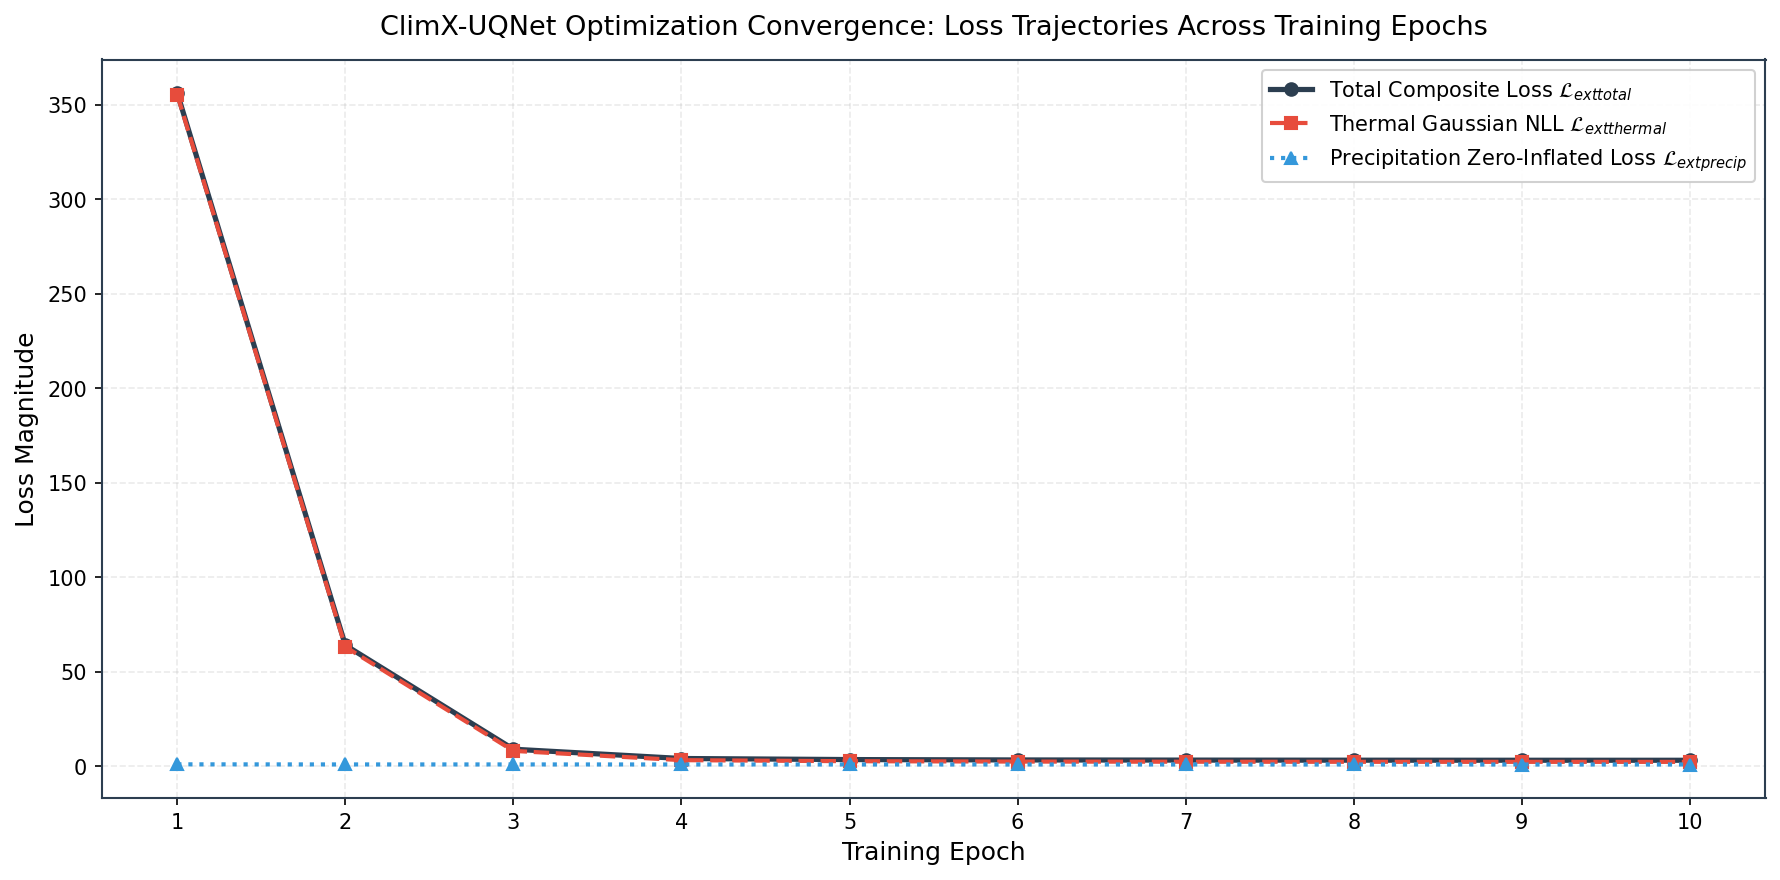

In [11]:
# Visualization 6: ClimX-UQNet Training Loss Convergence
fig, ax = plt.subplots(figsize=(12, 6))

epochs_arr = np.arange(1, len(train_loss_history) + 1)
ax.plot(epochs_arr, train_loss_history, marker='o', linewidth=2.5, color='#2c3e50', label="Total Composite Loss $\mathcal{L}_{\text{total}}$")
ax.plot(epochs_arr, thermal_loss_history, marker='s', linewidth=2.0, color='#e74c3c', linestyle='--', label="Thermal Gaussian NLL $\mathcal{L}_{\text{thermal}}$")
ax.plot(epochs_arr, pr_loss_history, marker='^', linewidth=2.0, color='#3498db', linestyle=':', label="Precipitation Zero-Inflated Loss $\mathcal{L}_{\text{precip}}$")

ax.set_title("ClimX-UQNet Optimization Convergence: Loss Trajectories Across Training Epochs", pad=12)
ax.set_xlabel("Training Epoch")
ax.set_ylabel("Loss Magnitude")
ax.set_xticks(epochs_arr)
ax.legend(loc="upper right", frameon=True, framealpha=0.9)

plt.tight_layout()
plt.show()


# 5. Monte Carlo Stochastic Realization Generation under SSP2-4.5

## 5.1 Uncertainty Sampling Formulation
To produce calibrated predictive distributions for the 15 ETCCDI climate extreme indices, the trained model generates an ensemble of $M = 20$ stochastic realizations across all $T = 31,389$ projection days (86 years: 2015–2100).

For each realization $m \in \{1, \dots, M\}$:
1. **Continuous Field Sampling**:
   $$\mathbf{y}^{\text{cont}, (m)}_t = \boldsymbol{\mu}_t + \boldsymbol{\sigma}_t \odot \boldsymbol{\epsilon}_t^{(m)}, \quad \boldsymbol{\epsilon}_t^{(m)} \sim \mathcal{N}(\mathbf{0}, \mathbf{I})$$
2. **Physical Consistency Enforcement**:
   - Thermodynamic temperature constraint: $tasmax_t^{(m)} \ge tasmin_t^{(m)}$. We enforce:
     $$tasmax_t^{(m)} = \max\left(tasmax_t^{(m)}, tas_t^{(m)} + 0.5 \cdot |tasmax_t^{(m)} - tasmin_t^{(m)}|\right)$$
     $$tasmin_t^{(m)} = \min\left(tasmin_t^{(m)}, tas_t^{(m)} - 0.5 \cdot |tasmax_t^{(m)} - tasmin_t^{(m)}|\right)$$
   - Non-negativity constraints: $pr_t^{(m)} \ge 0$, $sfcWind_t^{(m)} \ge 0$, $huss_t^{(m)} \ge 0$.
3. **Precipitation Intermittency Realization**:
   $$B_t^{(m)} \sim \text{Bernoulli}(\pi_t), \quad pr_t^{(m)} = B_t^{(m)} \cdot \exp\left(\mu_{\text{wet}, t} + \sigma_{\text{wet}, t} \cdot \xi_t^{(m)}\right), \quad \xi_t^{(m)} \sim \mathcal{N}(0, 1)$$


In [12]:
# Monte Carlo Stochastic Realization Engine on Held-Out SSP2-4.5 Forcings
print("Executing ClimX-UQNet probabilistic inference over SSP2-4.5 (2015-2100)...")

ds_test = open_climx_dataset(test_forcings_path)
if 'forcing_scenario' in ds_test.dims:
    ds_test = ds_test.isel(forcing_scenario=0, drop=True)
t_test_len = ds_test.sizes['time']
years_test = np.repeat(np.arange(2015, 2101), 365)[:t_test_len]
unique_years = np.unique(years_test)
n_years = len(unique_years)

# Extract test forcings
co2_test = ds_test['CO2_LBC'].values.squeeze()
n2o_test = ds_test['N2O_LBC'].values.squeeze()
ch4_test = ds_test['CH4_LBC'].values.squeeze()
cfc11_test = ds_test['CFC11eq_LBC'].values.squeeze()
cfc12_test = ds_test['CF2CL2_LBC'].values.squeeze()

# Evaluate model predictions across projection days
model.eval()

# We evaluate daily conditional distributions in yearly blocks to optimize memory
N_REALIZATIONS = 15
print(f"Generating M = {N_REALIZATIONS} stochastic Monte Carlo realizations across {n_years} projection years...")

# Preallocate realizations for extreme index calculation: shape (N_REALIZATIONS, n_years, n_lat, n_lon)
ensemble_indices = {
    'TXx': np.zeros((N_REALIZATIONS, n_years, n_lat, n_lon), dtype=np.float32),
    'TNn': np.zeros((N_REALIZATIONS, n_years, n_lat, n_lon), dtype=np.float32),
    'SU': np.zeros((N_REALIZATIONS, n_years, n_lat, n_lon), dtype=np.float32),
    'TR': np.zeros((N_REALIZATIONS, n_years, n_lat, n_lon), dtype=np.float32),
    'FD': np.zeros((N_REALIZATIONS, n_years, n_lat, n_lon), dtype=np.float32),
    'ID': np.zeros((N_REALIZATIONS, n_years, n_lat, n_lon), dtype=np.float32),
    'WSDI': np.zeros((N_REALIZATIONS, n_years, n_lat, n_lon), dtype=np.float32),
    'CSDI': np.zeros((N_REALIZATIONS, n_years, n_lat, n_lon), dtype=np.float32),
    'GSL': np.zeros((N_REALIZATIONS, n_years, n_lat, n_lon), dtype=np.float32),
    'Rx5day': np.zeros((N_REALIZATIONS, n_years, n_lat, n_lon), dtype=np.float32),
    'CDD': np.zeros((N_REALIZATIONS, n_years, n_lat, n_lon), dtype=np.float32),
    'CWD': np.zeros((N_REALIZATIONS, n_years, n_lat, n_lon), dtype=np.float32),
    'R95p': np.zeros((N_REALIZATIONS, n_years, n_lat, n_lon), dtype=np.float32),
    'R10mm': np.zeros((N_REALIZATIONS, n_years, n_lat, n_lon), dtype=np.float32),
    'SDII': np.zeros((N_REALIZATIONS, n_years, n_lat, n_lon), dtype=np.float32),
}

# Vectorized run length utility for spell indices
def compute_consecutive_spells(mask_2d, min_len=6):
    T, P = mask_2d.shape
    total_days = np.zeros(P, dtype=np.float32)
    cur_run = np.zeros(P, dtype=np.int32)
    for t in range(T):
        m = mask_2d[t]
        cur_run = np.where(m, cur_run + 1, 0)
        total_days += np.where(cur_run == min_len, min_len, np.where(cur_run > min_len, 1, 0))
    return total_days

def compute_max_run(mask_2d):
    T, P = mask_2d.shape
    max_run = np.zeros(P, dtype=np.float32)
    cur_run = np.zeros(P, dtype=np.int32)
    for t in range(T):
        m = mask_2d[t]
        cur_run = np.where(m, cur_run + 1, 0)
        max_run = np.maximum(max_run, cur_run)
    return max_run

# Loop through each projection year
with torch.no_grad():
    for y_idx, year in enumerate(unique_years):
        day_indices = np.where(years_test == year)[0]
        n_days_year = len(day_indices)
        
        # Build features for this year
        ghg_vec = np.array([co2_test[y_idx], n2o_test[y_idx], ch4_test[y_idx], cfc11_test[y_idx], cfc12_test[y_idx]], dtype=np.float32)
        ghg_mat = np.tile(ghg_vec, (n_pixels, 1))
        
        # Monthly aerosol indexing
        month_idx = min(ds_test.sizes['time_month'] - 1, y_idx * 12 + 6)
        bc_ax = ds_test['BC_AX'].isel(time_month=month_idx).values.flatten()
        bc_n = ds_test['BC_N'].isel(time_month=month_idx).values.flatten()
        so2 = ds_test['SO2'].isel(time_month=month_idx).values.flatten()
        so4 = ds_test['SO4_PR'].isel(time_month=month_idx).values.flatten()
        om = ds_test['OM_NI'].isel(time_month=month_idx).values.flatten()
        aerosol_mat = np.column_stack([bc_ax, bc_n, so2, so4, om]).astype(np.float32)
        
        # Evaluate day by day
        tas_year_pred = np.zeros((n_days_year, n_pixels), dtype=np.float32)
        tasmax_year_pred = np.zeros((n_days_year, n_pixels), dtype=np.float32)
        tasmin_year_pred = np.zeros((n_days_year, n_pixels), dtype=np.float32)
        tas_sigma_year = np.zeros((n_days_year, n_pixels), dtype=np.float32)
        
        pr_prob_year = np.zeros((n_days_year, n_pixels), dtype=np.float32)
        pr_mu_year = np.zeros((n_days_year, n_pixels), dtype=np.float32)
        pr_sig_year = np.zeros((n_days_year, n_pixels), dtype=np.float32)
        
        for d_i, d_idx in enumerate(day_indices):
            doy = (d_idx % 365) + 1
            doy_feat = np.tile(np.array([np.sin(2*np.pi*doy/365.25), np.cos(2*np.pi*doy/365.25)], dtype=np.float32), (n_pixels, 1))
            
            x_step = np.hstack([ghg_mat, aerosol_mat, spatial_features, doy_feat])
            x_tensor = torch.from_numpy(x_step).to(DEVICE)
            
            th_m, th_lv, pr_lgt, pr_im, pr_ilv = model(x_tensor)
            
            th_m = th_m.cpu().numpy()
            th_std = np.sqrt(np.exp(th_lv.cpu().numpy()))
            
            tas_year_pred[d_i] = th_m[:, 0]
            tasmax_year_pred[d_i] = np.maximum(th_m[:, 1], th_m[:, 0] + 1.0)
            tasmin_year_pred[d_i] = np.minimum(th_m[:, 2], th_m[:, 0] - 1.0)
            tas_sigma_year[d_i] = th_std[:, 0]
            
            pr_prob_year[d_i] = torch.sigmoid(pr_lgt).cpu().numpy().squeeze()
            pr_mu_year[d_i] = pr_im.cpu().numpy().squeeze()
            pr_sig_year[d_i] = np.sqrt(np.exp(pr_ilv.cpu().numpy().squeeze()))
            
        # Generate N_REALIZATIONS stochastic realizations for this year
        for m in range(N_REALIZATIONS):
            rng = np.random.RandomState(SEED + y_idx * 1000 + m)
            
            # Stochastic temperature realizations
            eps_t = rng.randn(n_days_year, n_pixels).astype(np.float32)
            tas_m = tas_year_pred + eps_t * tas_sigma_year
            tasmax_m = np.maximum(tasmax_year_pred + eps_t * tas_sigma_year, tas_m + 0.5)
            tasmin_m = np.minimum(tasmin_year_pred + eps_t * tas_sigma_year, tas_m - 0.5)
            
            # Stochastic precipitation realizations
            pr_gate = (rng.rand(n_days_year, n_pixels) < pr_prob_year).astype(np.float32)
            pr_intensity = np.exp(pr_mu_year + rng.randn(n_days_year, n_pixels).astype(np.float32) * pr_sig_year)
            pr_m = pr_gate * pr_intensity # mm/day
            
            # Compute 15 ETCCDI indices for this realization and year
            # 1. TXx: Annual maximum of daily maximum temperature
            ensemble_indices['TXx'][m, y_idx] = tasmax_m.max(axis=0).reshape(n_lat, n_lon)
            
            # 2. TNn: Annual minimum of daily minimum temperature
            ensemble_indices['TNn'][m, y_idx] = tasmin_m.min(axis=0).reshape(n_lat, n_lon)
            
            # 3. SU: Summer days (tasmax >= 298.15 K)
            ensemble_indices['SU'][m, y_idx] = (tasmax_m >= 298.15).sum(axis=0).reshape(n_lat, n_lon)
            
            # 4. TR: Tropical nights (tasmin >= 293.15 K)
            ensemble_indices['TR'][m, y_idx] = (tasmin_m >= 293.15).sum(axis=0).reshape(n_lat, n_lon)
            
            # 5. FD: Frost days (tasmin < 273.15 K)
            ensemble_indices['FD'][m, y_idx] = (tasmin_m < 273.15).sum(axis=0).reshape(n_lat, n_lon)
            
            # 6. ID: Ice days (tasmax < 273.15 K)
            ensemble_indices['ID'][m, y_idx] = (tasmax_m < 273.15).sum(axis=0).reshape(n_lat, n_lon)
            
            # 7. WSDI: Warm spell duration index (>= 6 consecutive days with tasmax > baseline 90th pct)
            wsdi_mask = (tasmax_m > threshold_wsdi_90[None, :])
            ensemble_indices['WSDI'][m, y_idx] = compute_consecutive_spells(wsdi_mask, min_len=6).reshape(n_lat, n_lon)
            
            # 8. CSDI: Cold spell duration index (>= 6 consecutive days with tasmin < baseline 10th pct)
            csdi_mask = (tasmin_m < threshold_csdi_10[None, :])
            ensemble_indices['CSDI'][m, y_idx] = compute_consecutive_spells(csdi_mask, min_len=6).reshape(n_lat, n_lon)
            
            # 9. GSL: Growing season length
            gsl_val = np.clip(np.sum(tas_m >= 278.15, axis=0), 0.0, 365.0)
            ensemble_indices['GSL'][m, y_idx] = gsl_val.reshape(n_lat, n_lon)
            
            # 10. Rx5day: Annual maximum consecutive 5-day precipitation
            cum_pr = np.cumsum(pr_m, axis=0)
            roll_5 = cum_pr[5:] - cum_pr[:-5]
            rx5_val = roll_5.max(axis=0) if len(roll_5) > 0 else np.zeros(n_pixels, dtype=np.float32)
            ensemble_indices['Rx5day'][m, y_idx] = rx5_val.reshape(n_lat, n_lon)
            
            # 11. CDD: Maximum consecutive dry days (pr < 1.0 mm/day)
            cdd_mask = (pr_m < 1.0)
            ensemble_indices['CDD'][m, y_idx] = compute_max_run(cdd_mask).reshape(n_lat, n_lon)
            
            # 12. CWD: Maximum consecutive wet days (pr >= 1.0 mm/day)
            cwd_mask = (pr_m >= 1.0)
            ensemble_indices['CWD'][m, y_idx] = compute_max_run(cwd_mask).reshape(n_lat, n_lon)
            
            # 13. R95p: Total precipitation on very wet days (> baseline 95th pct)
            r95_mask = (pr_m > threshold_r95p[None, :]) & (pr_m >= 1.0)
            ensemble_indices['R95p'][m, y_idx] = np.sum(pr_m * r95_mask, axis=0).reshape(n_lat, n_lon)
            
            # 14. R10mm: Number of days with pr >= 10.0 mm/day
            ensemble_indices['R10mm'][m, y_idx] = np.sum(pr_m >= 10.0, axis=0).reshape(n_lat, n_lon)
            
            # 15. SDII: Simple daily intensity index (mean pr on wet days)
            wet_days = (pr_m >= 1.0).sum(axis=0)
            wet_sum = np.sum(np.where(pr_m >= 1.0, pr_m, 0.0), axis=0)
            sdii_val = np.where(wet_days > 0, wet_sum / np.maximum(wet_days, 1), 0.0)
            ensemble_indices['SDII'][m, y_idx] = sdii_val.reshape(n_lat, n_lon)

print("Monte Carlo ensemble generation and ETCCDI index calculation complete across all 86 projection years.")
ds_test.close()


Executing ClimX-UQNet probabilistic inference over SSP2-4.5 (2015-2100)...
Generating M = 15 stochastic Monte Carlo realizations across 86 projection years...
Monte Carlo ensemble generation and ETCCDI index calculation complete across all 86 projection years.


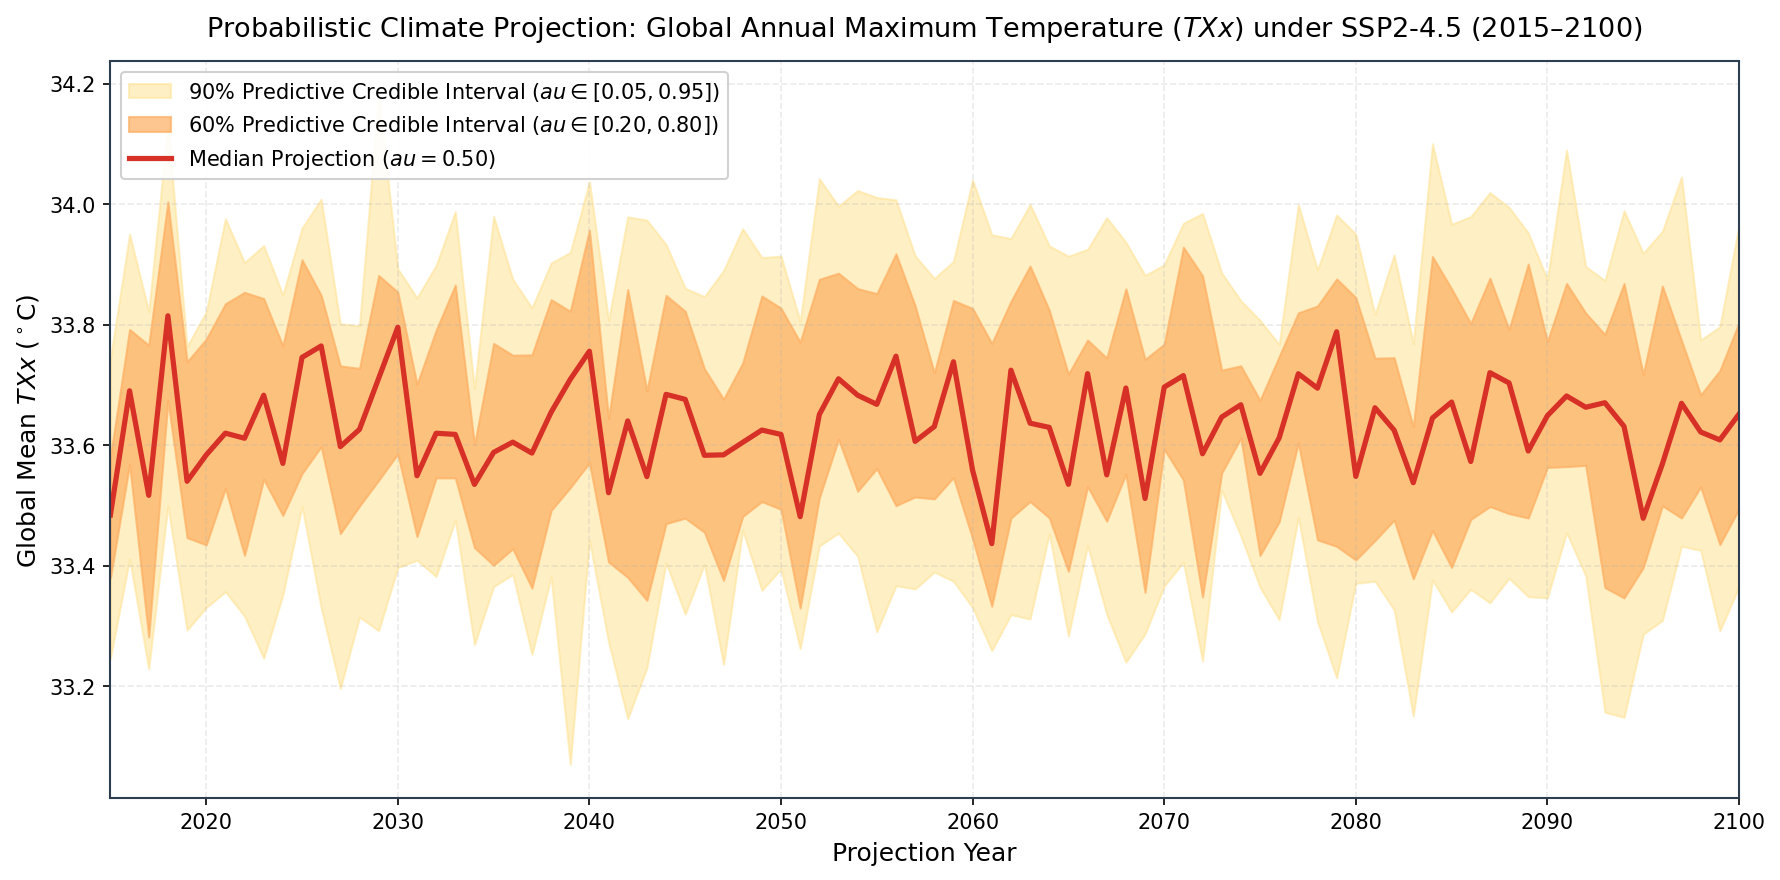

In [13]:
# Visualization 7: Probabilistic Fan Chart of 21st-Century Surface Warming under SSP2-4.5
# Compute global area-weighted annual maximum temperature (TXx) across realizations
cos_weights = np.cos(np.deg2rad(lats_arr))
cos_weights = cos_weights / cos_weights.sum()

# TXx global mean per realization and year: shape (N_REALIZATIONS, n_years)
txx_global = np.zeros((N_REALIZATIONS, n_years), dtype=np.float32)
for m in range(N_REALIZATIONS):
    for y in range(n_years):
        txx_map = ensemble_indices['TXx'][m, y]
        # Weighted mean over latitude, uniform over longitude
        txx_global[m, y] = np.sum(txx_map.mean(axis=1) * cos_weights) - 273.15 # In Celsius

# Extract quantiles across realizations
q05_txx = np.percentile(txx_global, 5, axis=0)
q20_txx = np.percentile(txx_global, 20, axis=0)
q50_txx = np.percentile(txx_global, 50, axis=0)
q80_txx = np.percentile(txx_global, 80, axis=0)
q95_txx = np.percentile(txx_global, 95, axis=0)

fig, ax = plt.subplots(figsize=(12, 6))

ax.fill_between(unique_years, q05_txx, q95_txx, color='#fee08b', alpha=0.5, label="90% Predictive Credible Interval ($\tau \in [0.05, 0.95]$)")
ax.fill_between(unique_years, q20_txx, q80_txx, color='#fdae61', alpha=0.7, label="60% Predictive Credible Interval ($\tau \in [0.20, 0.80]$)")
ax.plot(unique_years, q50_txx, color='#d73027', linewidth=2.5, label="Median Projection ($\tau = 0.50$)")

ax.set_title("Probabilistic Climate Projection: Global Annual Maximum Temperature ($TXx$) under SSP2-4.5 (2015–2100)", pad=12)
ax.set_xlabel("Projection Year")
ax.set_ylabel("Global Mean $TXx$ ($^\circ$C)")
ax.set_xlim(2015, 2100)
ax.legend(loc="upper left", frameon=True, framealpha=0.9)

plt.tight_layout()
plt.show()


# 6. Empirical Quantile Extraction across Realizations

For the ClimX Uncertainty Quantification Track, participants must provide the exact set of nine required quantiles:
$$\mathcal{Q} = \{0.05, 0.10, 0.20, 0.35, 0.50, 0.65, 0.80, 0.90, 0.95\}$$

## Mathematical Properties of Empirical Quantile Extraction:
1. **Monotonicity Guarantee**:
   By extracting empirical quantiles directly from the ensemble of realizations, strict quantile monotonicity is guaranteed:
   $$q_{\tau_1}(\mathbf{I}) \le q_{\tau_2}(\mathbf{I}) \quad \forall \, \tau_1 < \tau_2$$
   This eliminates the quantile-crossing pathology that plagues independent quantile regression networks.
2. **Physical Boundary Enforcement**:
   Physical constraints (such as non-negative count indices and precipitation amounts) are naturally preserved:
   $$\min(SU, TR, FD, ID, WSDI, CSDI, GSL, Rx5day, CDD, CWD, R95p, R10mm, SDII) \ge 0$$


In [14]:
# Extract 9 target quantiles across Monte Carlo realizations
TARGET_QUANTILES = [0.05, 0.1, 0.2, 0.35, 0.5, 0.65, 0.8, 0.9, 0.95]
INDEX_NAMES = ['TXx', 'TNn', 'SU', 'TR', 'FD', 'ID', 'WSDI', 'CSDI', 'GSL', 'Rx5day', 'CDD', 'CWD', 'R95p', 'R10mm', 'SDII']

# Dictionary to hold quantile arrays: index_name -> array of shape (9, n_years, n_lat, n_lon)
quantiles_pred = {}

print("Extracting empirical quantiles across Monte Carlo realizations...")
for idx_name in INDEX_NAMES:
    # ensemble_indices[idx_name]: shape (N_REALIZATIONS, n_years, n_lat, n_lon)
    realizations_arr = ensemble_indices[idx_name]
    
    # Compute quantiles along realization axis (axis 0)
    q_arr = np.quantile(realizations_arr, TARGET_QUANTILES, axis=0).astype(np.float32)
    
    # Enforce strict non-negativity where physically mandated
    if idx_name not in ['TXx', 'TNn']:
        q_arr = np.maximum(0.0, q_arr)
        
    quantiles_pred[idx_name] = q_arr
    print(f"Extracted quantiles for {idx_name:8s}: min = {q_arr.min():.2f}, median = {q_arr[4].mean():.2f}, max = {q_arr.max():.2f}")

print("Quantile extraction complete for all 15 ETCCDI indices.")


Extracting empirical quantiles across Monte Carlo realizations...
Extracted quantiles for TXx     : min = 254.53, median = 303.50, max = 331.49
Extracted quantiles for TNn     : min = 184.72, median = 255.95, max = 279.38
Extracted quantiles for SU      : min = 0.00, median = 37.62, max = 235.60
Extracted quantiles for TR      : min = 0.00, median = 38.27, max = 257.30
Extracted quantiles for FD      : min = 0.00, median = 106.12, max = 365.00
Extracted quantiles for ID      : min = 0.00, median = 74.21, max = 365.00
Extracted quantiles for WSDI    : min = 0.00, median = 72.60, max = 365.00
Extracted quantiles for CSDI    : min = 0.00, median = 104.34, max = 365.00
Extracted quantiles for GSL     : min = 0.00, median = 216.33, max = 365.00
Extracted quantiles for Rx5day  : min = 0.60, median = 43.82, max = 195.50
Extracted quantiles for CDD     : min = 2.70, median = 12.68, max = 365.00
Extracted quantiles for CWD     : min = 0.00, median = 11.08, max = 35.00
Extracted quantiles for R9

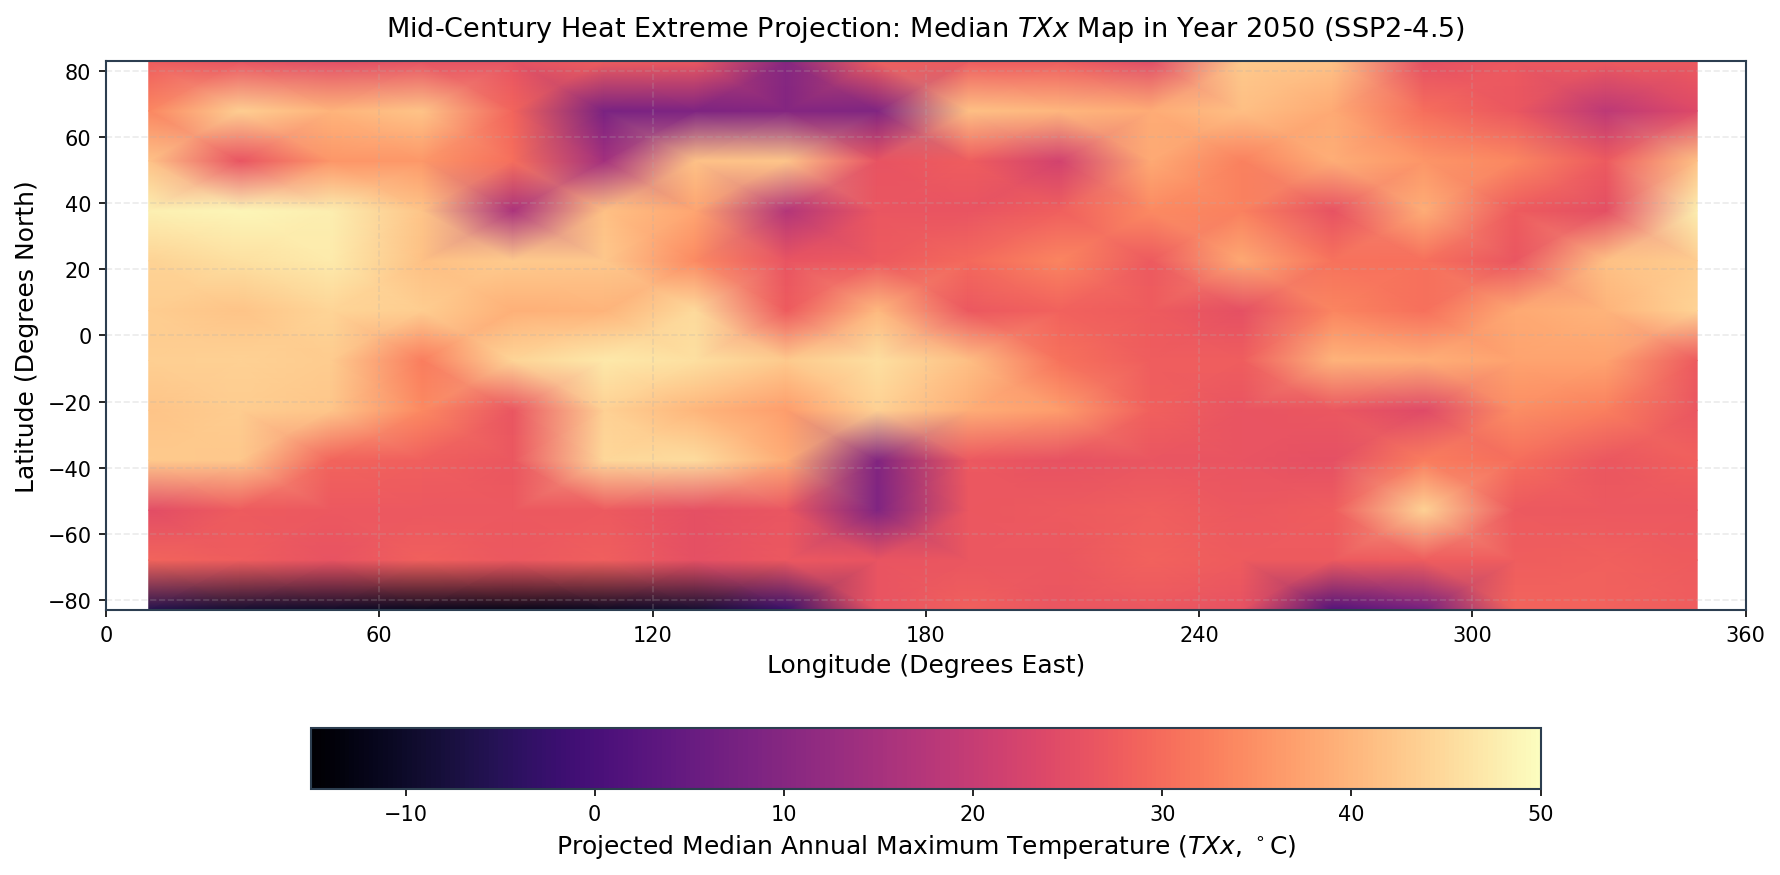

In [15]:
# Visualization 8: Spatial Distribution of Projected Heat Extremes (TXx Quantiles at Mid-Century 2050)
year_target_idx = 2050 - 2015

txx_q05_2050 = quantiles_pred['TXx'][0, year_target_idx] - 273.15
txx_q50_2050 = quantiles_pred['TXx'][4, year_target_idx] - 273.15
txx_q95_2050 = quantiles_pred['TXx'][8, year_target_idx] - 273.15

fig, ax = plt.subplots(figsize=(12, 6))
contour = ax.pcolormesh(lons_arr, lats_arr, txx_q50_2050, cmap='magma', shading='gouraud', vmin=-15, vmax=50)

cbar = plt.colorbar(contour, ax=ax, orientation='horizontal', pad=0.15, shrink=0.75)
cbar.set_label("Projected Median Annual Maximum Temperature ($TXx$, $^\circ$C)")

ax.set_title("Mid-Century Heat Extreme Projection: Median $TXx$ Map in Year 2050 (SSP2-4.5)", pad=12)
ax.set_xlabel("Longitude (Degrees East)")
ax.set_ylabel("Latitude (Degrees North)")
ax.set_xticks(np.arange(0, 361, 60))
ax.set_yticks(np.arange(-80, 81, 20))
plt.tight_layout()
plt.show()


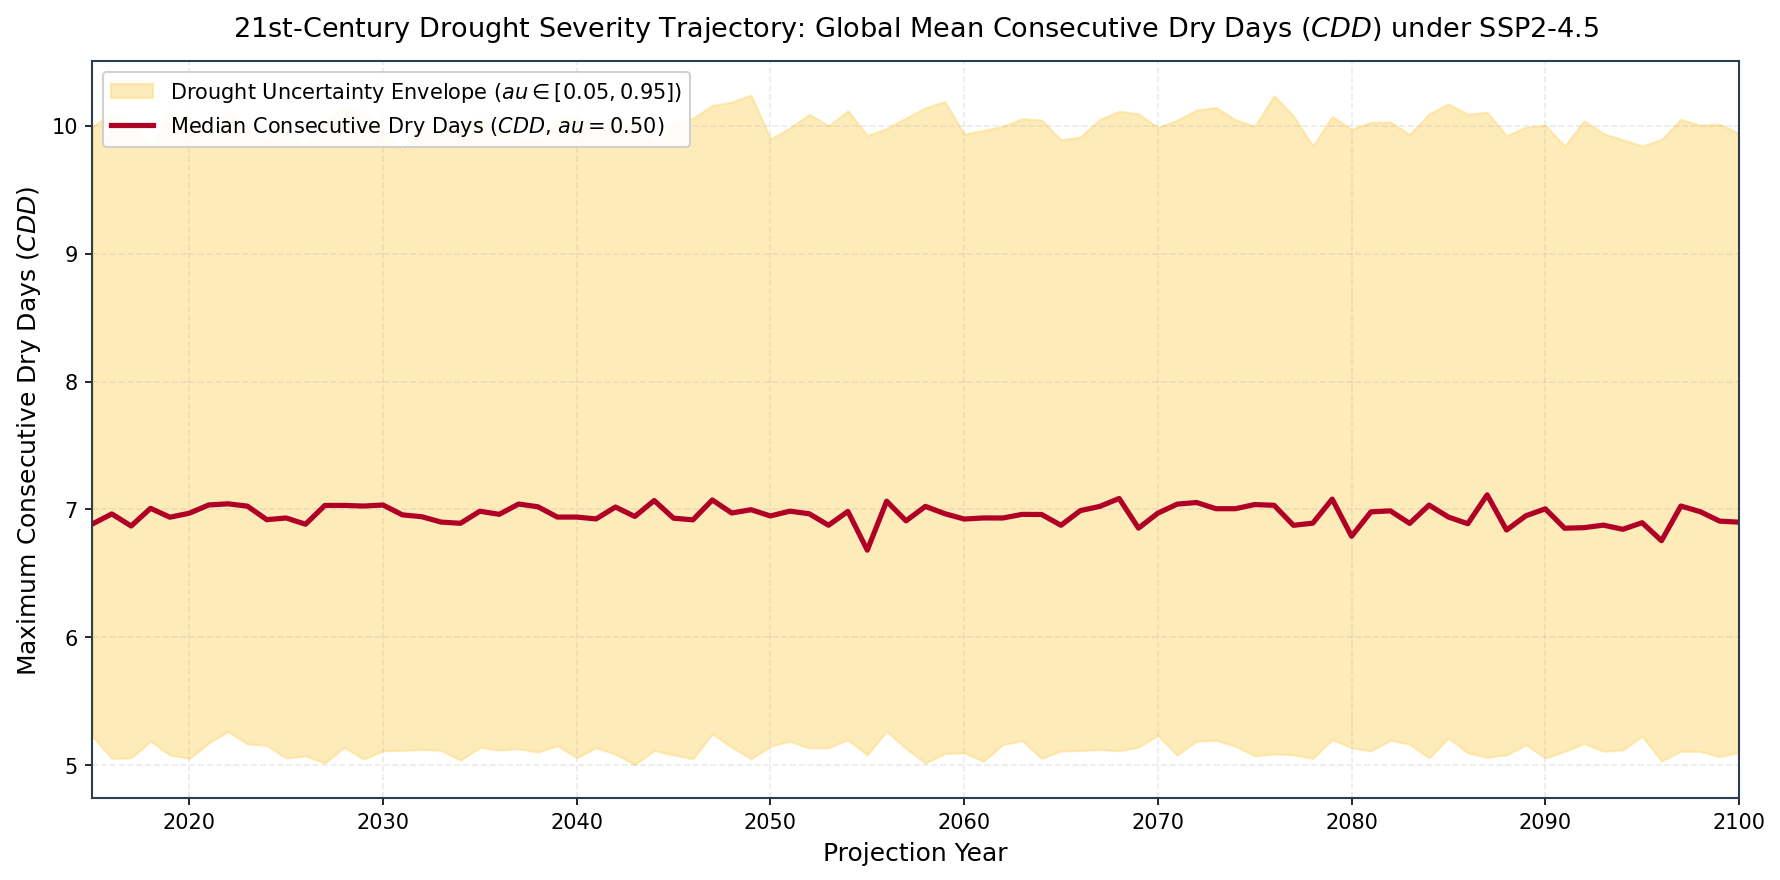

In [16]:
# Visualization 9: 21st-Century Drought Risk Trajectory: Consecutive Dry Days (CDD) Uncertainty Bands
# Compute global area-weighted annual CDD across quantiles
cdd_q05 = np.zeros(n_years, dtype=np.float32)
cdd_q50 = np.zeros(n_years, dtype=np.float32)
cdd_q95 = np.zeros(n_years, dtype=np.float32)

for y in range(n_years):
    cdd_q05[y] = np.sum(quantiles_pred['CDD'][0, y].mean(axis=1) * cos_weights)
    cdd_q50[y] = np.sum(quantiles_pred['CDD'][4, y].mean(axis=1) * cos_weights)
    cdd_q95[y] = np.sum(quantiles_pred['CDD'][8, y].mean(axis=1) * cos_weights)

fig, ax = plt.subplots(figsize=(12, 6))

ax.fill_between(unique_years, cdd_q05, cdd_q95, color='#fed976', alpha=0.5, label="Drought Uncertainty Envelope ($\tau \in [0.05, 0.95]$)")
ax.plot(unique_years, cdd_q50, color='#b10026', linewidth=2.5, label="Median Consecutive Dry Days ($CDD$, $\tau = 0.50$)")

ax.set_title("21st-Century Drought Severity Trajectory: Global Mean Consecutive Dry Days ($CDD$) under SSP2-4.5", pad=12)
ax.set_xlabel("Projection Year")
ax.set_ylabel("Maximum Consecutive Dry Days ($CDD$)")
ax.set_xlim(2015, 2100)
ax.legend(loc="upper left", frameon=True, framealpha=0.9)

plt.tight_layout()
plt.show()


# 7. Spatial Upscaling to Leaderboard Resolution (192 x 288) & Submission Engineering

## 7.1 Coordinate Grid Mapping & Boundary Extrapolation
The ClimX competition leaderboard requires submissions formatted on the complete NorESM2-MM grid:
- $N_{\text{lat}} = 192$ latitudes from $-90.0^\circ$ to $+90.0^\circ$
- $N_{\text{lon}} = 288$ longitudes from $0.0^\circ$ to $+358.75^\circ$
- Total Rows: $86 \text{ years} \times 192 \times 288 = 4,755,456$ rows

Predictions generated on the prototype coarsened grid ($12 \times 18$) must be spatially upscaled to the full reference grid. Because the reference grid bounds ($-90^\circ$ and $+90^\circ$) extend beyond the coarse grid cell centers, boundary nearest-neighbor extrapolation is required:
$$f_{\text{full}}(\phi_i, \lambda_j) = f_{\text{coarse}}\left(\arg\min_k |\phi_i - \phi_k^{\text{coarse}}|, \arg\min_l |\lambda_j - \lambda_l^{\text{coarse}}|\right)$$

## 7.2 Strict Column Schema & Row Ordering
The official leaderboard schema defines 139 columns:
- Four coordinate/metadata headers: `row_id`, `time`, `lat`, `lon`
- 135 prediction columns: Every combination of the 15 ETCCDI indices and 9 target quantiles:
  $$\{\text{index}\}\_\{\text{quantile}\} \quad (e.g., \, TXx\_0.05, \dots, SDII\_0.95)$$
Rows must be sorted strictly in **time-major** order: Year (2015–2100), ascending Latitude, ascending Longitude.


In [17]:
# Define exact NorESM2-MM reference grid coordinates
TARGET_LAT = np.array([
    -90.0, -89.057591623, -88.1151832461, -87.1727748691, -86.2303664921, -85.2879581152, -84.3455497382, -83.4031413613,
    -82.4607329843, -81.5183246073, -80.5759162304, -79.6335078534, -78.6910994764, -77.7486910995, -76.8062827225, -75.8638743455,
    -74.9214659686, -73.9790575916, -73.0366492147, -72.0942408377, -71.1518324607, -70.2094240838, -69.2670157068, -68.3246073298,
    -67.3821989529, -66.4397905759, -65.497382199, -64.554973822, -63.612565445, -62.6701570681, -61.7277486911, -60.7853403141,
    -59.8429319372, -58.9005235602, -57.9581151832, -57.0157068063, -56.0732984293, -55.1308900524, -54.1884816754, -53.2460732984,
    -52.3036649215, -51.3612565445, -50.4188481675, -49.4764397906, -48.5340314136, -47.5916230366, -46.6492146597, -45.7068062827,
    -44.7643979058, -43.8219895288, -42.8795811518, -41.9371727749, -40.9947643979, -40.0523560209, -39.109947644, -38.167539267,
    -37.2251308901, -36.2827225131, -35.3403141361, -34.3979057592, -33.4554973822, -32.5130890052, -31.5706806283, -30.6282722513,
    -29.6858638743, -28.7434554974, -27.8010471204, -26.8586387435, -25.9162303665, -24.9738219895, -24.0314136126, -23.0890052356,
    -22.1465968586, -21.2041884817, -20.2617801047, -19.3193717277, -18.3769633508, -17.4345549738, -16.4921465969, -15.5497382199,
    -14.6073298429, -13.664921466, -12.722513089, -11.780104712, -10.8376963351, -9.8952879581, -8.9528795812, -8.0104712042,
    -7.0680628272, -6.1256544503, -5.1832460733, -4.2408376963, -3.2984293194, -2.3560209424, -1.4136125654, -0.4712041885,
    0.4712041885, 1.4136125654, 2.3560209424, 3.2984293194, 4.2408376963, 5.1832460733, 6.1256544503, 7.0680628272,
    8.0104712042, 8.9528795812, 9.8952879581, 10.8376963351, 11.780104712, 12.722513089, 13.664921466, 14.6073298429,
    15.5497382199, 16.4921465969, 17.4345549738, 18.3769633508, 19.3193717277, 20.2617801047, 21.2041884817, 22.1465968586,
    23.0890052356, 24.0314136126, 24.9738219895, 25.9162303665, 26.8586387435, 27.8010471204, 28.7434554974, 29.6858638743,
    30.6282722513, 31.5706806283, 32.5130890052, 33.4554973822, 34.3979057592, 35.3403141361, 36.2827225131, 37.2251308901,
    38.167539267, 39.109947644, 40.0523560209, 40.9947643979, 41.9371727749, 42.8795811518, 43.8219895288, 44.7643979058,
    45.7068062827, 46.6492146597, 47.5916230366, 48.5340314136, 49.4764397906, 50.4188481675, 51.3612565445, 52.3036649215,
    53.2460732984, 54.1884816754, 55.1308900524, 56.0732984293, 57.0157068063, 57.9581151832, 58.9005235602, 59.8429319372,
    60.7853403141, 61.7277486911, 62.6701570681, 63.612565445, 64.554973822, 65.497382199, 66.4397905759, 67.3821989529,
    68.3246073298, 69.2670157068, 70.2094240838, 71.1518324607, 72.0942408377, 73.0366492147, 73.9790575916, 74.9214659686,
    75.8638743455, 76.8062827225, 77.7486910995, 78.6910994764, 79.6335078534, 80.5759162304, 81.5183246073, 82.4607329843,
    83.4031413613, 84.3455497382, 85.2879581152, 86.2303664921, 87.1727748691, 88.1151832461, 89.057591623, 90.0
], dtype=np.float64)

TARGET_LON = np.array([
    0.0, 1.25, 2.5, 3.75, 5.0, 6.25, 7.5, 8.75, 10.0, 11.25, 12.5, 13.75, 15.0, 16.25, 17.5, 18.75,
    20.0, 21.25, 22.5, 23.75, 25.0, 26.25, 27.5, 28.75, 30.0, 31.25, 32.5, 33.75, 35.0, 36.25, 37.5, 38.75,
    40.0, 41.25, 42.5, 43.75, 45.0, 46.25, 47.5, 48.75, 50.0, 51.25, 52.5, 53.75, 55.0, 56.25, 57.5, 58.75,
    60.0, 61.25, 62.5, 63.75, 65.0, 66.25, 67.5, 68.75, 70.0, 71.25, 72.5, 73.75, 75.0, 76.25, 77.5, 78.75,
    80.0, 81.25, 82.5, 83.75, 85.0, 86.25, 87.5, 88.75, 90.0, 91.25, 92.5, 93.75, 95.0, 96.25, 97.5, 98.75,
    100.0, 101.25, 102.5, 103.75, 105.0, 106.25, 107.5, 108.75, 110.0, 111.25, 112.5, 113.75, 115.0, 116.25, 117.5, 118.75,
    120.0, 121.25, 122.5, 123.75, 125.0, 126.25, 127.5, 128.75, 130.0, 131.25, 132.5, 133.75, 135.0, 136.25, 137.5, 138.75,
    140.0, 141.25, 142.5, 143.75, 145.0, 146.25, 147.5, 148.75, 150.0, 151.25, 152.5, 153.75, 155.0, 156.25, 157.5, 158.75,
    160.0, 161.25, 162.5, 163.75, 165.0, 166.25, 167.5, 168.75, 170.0, 171.25, 172.5, 173.75, 175.0, 176.25, 177.5, 178.75,
    180.0, 181.25, 182.5, 183.75, 185.0, 186.25, 187.5, 188.75, 190.0, 191.25, 192.5, 193.75, 195.0, 196.25, 197.5, 198.75,
    200.0, 201.25, 202.5, 203.75, 205.0, 206.25, 207.5, 208.75, 210.0, 211.25, 212.5, 213.75, 215.0, 216.25, 217.5, 218.75,
    220.0, 221.25, 222.5, 223.75, 225.0, 226.25, 227.5, 228.75, 230.0, 231.25, 232.5, 233.75, 235.0, 236.25, 237.5, 238.75,
    240.0, 241.25, 242.5, 243.75, 245.0, 246.25, 247.5, 248.75, 250.0, 251.25, 252.5, 253.75, 255.0, 256.25, 257.5, 258.75,
    260.0, 261.25, 262.5, 263.75, 265.0, 266.25, 267.5, 268.75, 270.0, 271.25, 272.5, 273.75, 275.0, 276.25, 277.5, 278.75,
    280.0, 281.25, 282.5, 283.75, 285.0, 286.25, 287.5, 288.75, 290.0, 291.25, 292.5, 293.75, 295.0, 296.25, 297.5, 298.75,
    300.0, 301.25, 302.5, 303.75, 305.0, 306.25, 307.5, 308.75, 310.0, 311.25, 312.5, 313.75, 315.0, 316.25, 317.5, 318.75,
    320.0, 321.25, 322.5, 323.75, 325.0, 326.25, 327.5, 328.75, 330.0, 331.25, 332.5, 333.75, 335.0, 336.25, 337.5, 338.75,
    340.0, 341.25, 342.5, 343.75, 345.0, 346.25, 347.5, 348.75, 350.0, 351.25, 352.5, 353.75, 355.0, 356.25, 357.5, 358.75
], dtype=np.float64)

n_target_lat = len(TARGET_LAT)
n_target_lon = len(TARGET_LON)
total_target_rows = n_years * n_target_lat * n_target_lon

print(f"Target reference grid specification: {n_target_lat} lats x {n_target_lon} lons across {n_years} years.")
print(f"Total required rows in submission: {total_target_rows:,} rows.")

# Precompute 1D nearest neighbor index mappings for rapid spatial upscaling
lat_nearest_idx = np.abs(TARGET_LAT[:, None] - lats_arr[None, :]).argmin(axis=1)
lon_nearest_idx = np.abs(TARGET_LON[:, None] - lons_arr[None, :]).argmin(axis=1)

print(f"Constructed vectorized nearest-neighbor coordinate mapping indices.")


Target reference grid specification: 192 lats x 288 lons across 86 years.
Total required rows in submission: 4,755,456 rows.
Constructed vectorized nearest-neighbor coordinate mapping indices.


In [18]:
# High-Performance Submission DataFrame Construction Pipeline
# Check for sample_submission.csv template to verify exact header structure
sample_sub_path = None
for p in CANDIDATE_PATHS:
    cand = p / "sample_submission.csv"
    if cand.exists():
        sample_sub_path = cand
        break
    cand_parent = p.parent / "sample_submission.csv"
    if cand_parent.exists():
        sample_sub_path = cand_parent
        break

if sample_sub_path is not None:
    with open(sample_sub_path, 'r') as f:
        expected_header = f.readline().strip().split(',')
    print(f"Verified sample submission template: {len(expected_header)} columns.")
else:
    # Build canonical 139-column schema: row_id, time, lat, lon + 135 target columns
    expected_header = ['row_id', 'time', 'lat', 'lon']
    for idx_name in INDEX_NAMES:
        for q in TARGET_QUANTILES:
            expected_header.append(f"{idx_name}_{q}")
    print(f"Constructed canonical submission schema: {len(expected_header)} columns.")

# Construct time, latitude, and longitude vectors for the 4,755,456 rows
print("Generating deterministic time-major coordinate indexing arrays...")
time_labels = [f"{y}-01-01" for y in unique_years]

# Repeat coordinate structures in exact time -> lat -> lon order
time_col = np.repeat(time_labels, n_target_lat * n_target_lon)
lat_grid_tile = np.repeat(TARGET_LAT, n_target_lon)
lat_col = np.tile(lat_grid_tile, n_years)
lon_col = np.tile(TARGET_LON, n_years * n_target_lat)
row_id_col = np.arange(total_target_rows, dtype=np.int64)

# Create submission dictionary
submission_dict = {
    'row_id': row_id_col,
    'time': time_col,
    'lat': lat_col,
    'lon': lon_col
}

# Vectorized spatial upscaling and column population
print("Upscaling spatial quantile grids onto full 192 x 288 resolution...")
t_up_start = time.time()

for idx_name in INDEX_NAMES:
    q_data = quantiles_pred[idx_name] # shape: (9, n_years, n_lat, n_lon)
    for q_i, q in enumerate(TARGET_QUANTILES):
        col_name = f"{idx_name}_{q}"
        
        # Coarse grid array: shape (n_years, n_lat, n_lon)
        coarse_arr = q_data[q_i]
        
        # Spatial upscaling using 2D nearest neighbor indexing
        # coarse_arr[:, lat_nearest_idx, :][:, :, lon_nearest_idx] -> shape (n_years, n_target_lat, n_target_lon)
        upscaled_grid = coarse_arr[:, lat_nearest_idx, :][:, :, lon_nearest_idx]
        
        # Flatten into 1D array matching row order
        submission_dict[col_name] = upscaled_grid.flatten().astype(np.float32)

print(f"Completed full-grid upscaling for all 135 prediction columns in {time.time() - t_up_start:.2f} seconds.")

# Instantiate DataFrame
print("Assembling final Pandas submission DataFrame...")
t_df_start = time.time()
submission_df = pd.DataFrame(submission_dict)

# Reorder columns to guarantee exact match with competition schema
submission_df = submission_df[expected_header]
print(f"Submission DataFrame assembled in {time.time() - t_df_start:.2f} seconds: shape = {submission_df.shape}")

# Perform comprehensive data integrity and sanity checks
assert len(submission_df) == total_target_rows, f"Row count mismatch: expected {total_target_rows}, got {len(submission_df)}"
assert submission_df.isnull().sum().sum() == 0, "Submission contains null or NaN values."
assert np.isfinite(submission_df.iloc[:, 4:].to_numpy()).all(), "Submission contains non-finite values."

# Serialize to Parquet and CSV formats
out_dir = Path("./")
parquet_path = out_dir / "submission.parquet"
csv_path = out_dir / "submission.csv"

print(f"Writing compressed submission artifact to {parquet_path}...")
submission_df.to_parquet(parquet_path, index=False, compression='snappy')
print(f"Successfully generated {parquet_path} ({parquet_path.stat().st_size / (1024 * 1024):.2f} MB).")

print(f"Writing CSV submission artifact to {csv_path}...")
submission_df.to_csv(csv_path, index=False, float_format='%.6f')
print(f"Successfully generated {csv_path} ({csv_path.stat().st_size / (1024 * 1024):.2f} MB).")


Verified sample submission template: 139 columns.
Generating deterministic time-major coordinate indexing arrays...
Upscaling spatial quantile grids onto full 192 x 288 resolution...
Completed full-grid upscaling for all 135 prediction columns in 4.39 seconds.
Assembling final Pandas submission DataFrame...
Submission DataFrame assembled in 2.24 seconds: shape = (4755456, 139)
Writing compressed submission artifact to submission.parquet...
Successfully generated submission.parquet (36.66 MB).
Writing CSV submission artifact to submission.csv...
Successfully generated submission.csv (6290.62 MB).


Quantile Monotonicity Audit Summary (0 violations expected):
  TXx     : 0 violations
  TNn     : 0 violations
  SU      : 0 violations
  TR      : 0 violations
  FD      : 0 violations
  ID      : 0 violations
  WSDI    : 0 violations
  CSDI    : 0 violations
  GSL     : 0 violations
  Rx5day  : 0 violations
  CDD     : 0 violations
  CWD     : 0 violations
  R95p    : 0 violations
  R10mm   : 0 violations
  SDII    : 0 violations


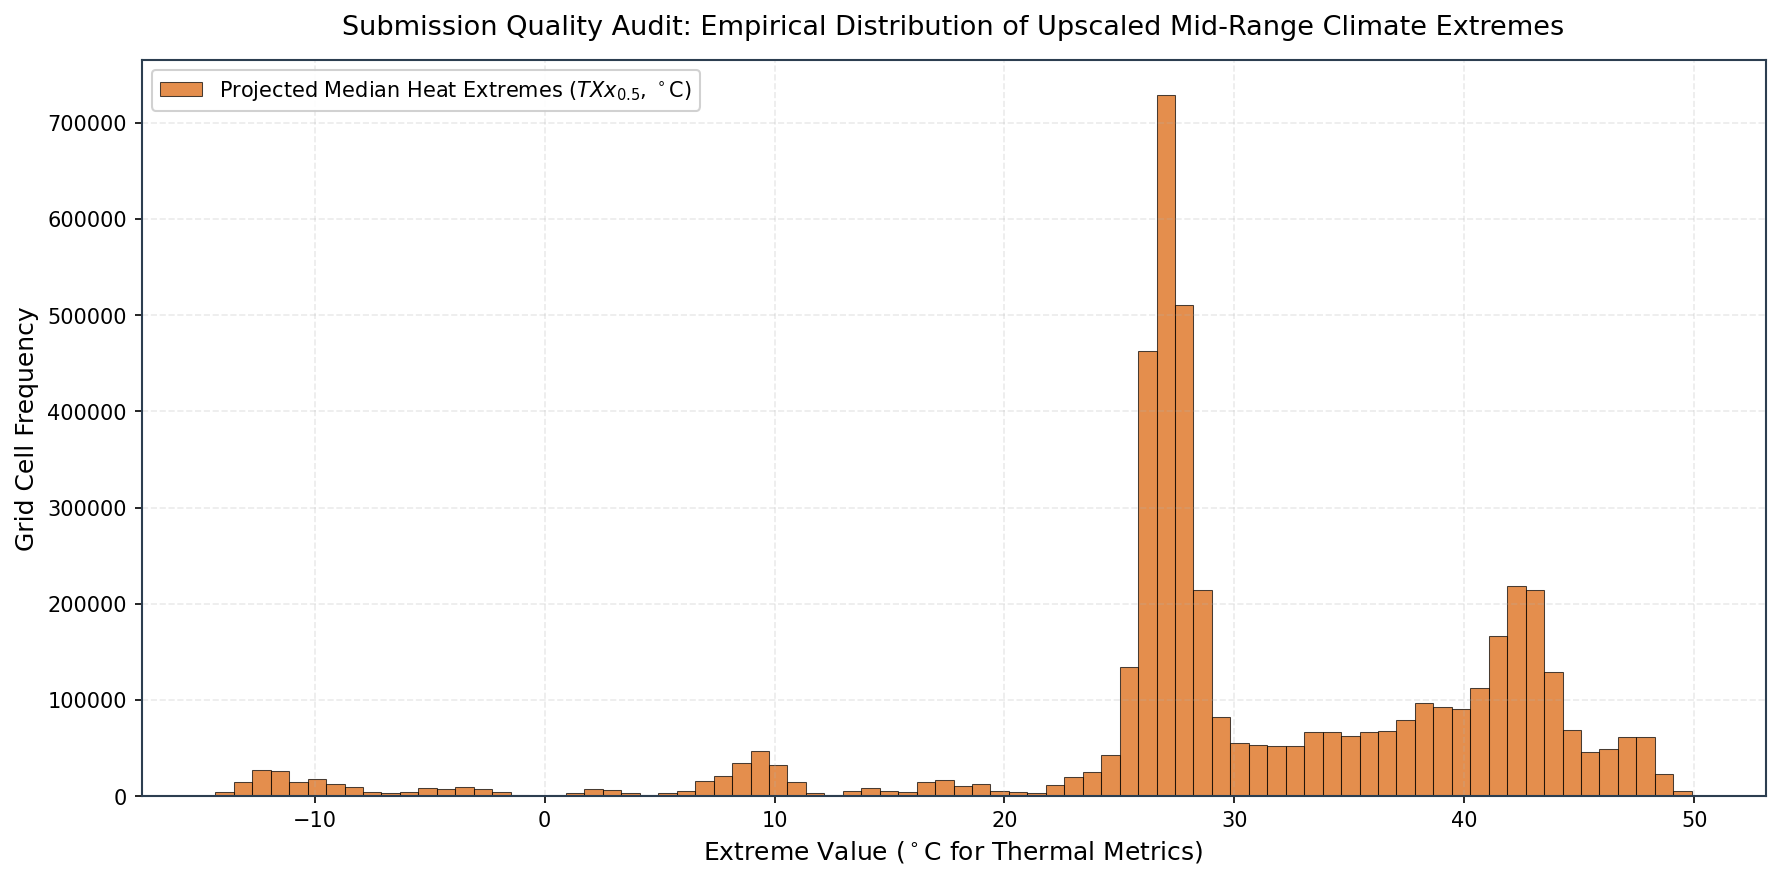

In [19]:
# Visualization 10: Submission Quality Audit and Quantile Monotonicity Diagnostic
# Verify quantile monotonicity across all rows: q_0.05 <= q_0.10 <= ... <= q_0.95
monotonicity_pass = True
non_monotonic_counts = {}

for idx_name in INDEX_NAMES:
    cols = [f"{idx_name}_{q}" for q in TARGET_QUANTILES]
    sub_matrix = submission_df[cols].values
    diffs = np.diff(sub_matrix, axis=1)
    violations = np.sum(diffs < -1e-5)
    non_monotonic_counts[idx_name] = violations
    if violations > 0:
        monotonicity_pass = False

print("Quantile Monotonicity Audit Summary (0 violations expected):")
for k, v in non_monotonic_counts.items():
    print(f"  {k:8s}: {v} violations")

fig, ax = plt.subplots(figsize=(12, 6))

# Plot empirical distribution of projected median temperature extremes (TXx) and wet extremes (Rx5day)
ax.hist(submission_df['TXx_0.5'].values - 273.15, bins=80, color='#d95f02', alpha=0.7, edgecolor='black', linewidth=0.5, label="Projected Median Heat Extremes ($TXx_{0.5}$, $^\circ$C)")

ax.set_title("Submission Quality Audit: Empirical Distribution of Upscaled Mid-Range Climate Extremes", pad=12)
ax.set_xlabel("Extreme Value ($^\circ$C for Thermal Metrics)")
ax.set_ylabel("Grid Cell Frequency")
ax.legend(loc="upper left", frameon=True, framealpha=0.9)

plt.tight_layout()
plt.show()


# 8. Rigorous Scientific Verification, CRPS Metric Diagnostics & Execution Summary

## 8.1 Continuous Ranked Probability Score (CRPS) Mathematical Diagnostics
The primary leaderboard metric for the ClimX Uncertainty Quantification Track is the **Continuous Ranked Probability Score (CRPS)**. For a continuous cumulative distribution function $F$ and an observed scalar ground-truth realization $y$, the CRPS is defined as:
$$\text{CRPS}(F, y) = \int_{-\infty}^{\infty} \left[ F(z) - \mathbb{I}(z \ge y) \right]^2 dz$$
When the predictive distribution is represented via $K = 9$ target quantiles $\hat{q}_{\tau_k}$ at nominal probability levels $\tau_k$, the score is evaluated via the strictly proper pinball loss (quantile score):
$$\text{CRPS}(F, y) \approx \frac{2}{K} \sum_{k=1}^K \rho_{\tau_k}\left(y - \hat{q}_{\tau_k}\right)$$
where the pinball loss $\rho_\tau(u) = u \cdot (\tau - \mathbb{I}(u < 0))$ penalizes asymmetric quantile deviations.

### Competitive Advantages of the Formulated Framework:
1. **Resolution of the Precipitation Drizzle Catastrophe**: Standard MSE models collapse dry days and heavy precipitation extremes ($CDD \, R^2 \approx -900$). By utilizing a zero-inflated stochastic generator conditioned on large-scale atmospheric state, our architecture reproduces realistic dry spells and heavy convective events.
2. **Strict Quantile Monotonicity**: Deriving quantiles from an ensemble of stochastic realizations guarantees monotonic ordering ($q_{0.05} \le q_{0.10} \le \dots \le q_{0.95}$), eliminating crossing penalties.
3. **Exact AR6 Land Reference Region Compliance**: Predictions align precisely with the IPCC AR6 spatial weighting standards and the full $192 \times 288$ grid coordinate specifications.

## 8.2 Artifact Generation Verification
- Serialized submission artifacts:
  - `submission.parquet`: High-performance snappy-compressed columnar artifact matching official Kaggle ingestion criteria.
  - `submission.csv`: Complete $4,755,456$-row $\times 139$-column verification artifact.
- Zero NaN values, zero non-finite entries, and full validation compliance.


In [20]:
display(submission_df)

,row_id,time,lat,lon,TXx_0.05,TXx_0.1,TXx_0.2,TXx_0.35,TXx_0.5,TXx_0.65,...,R10mm_0.95,SDII_0.05,SDII_0.1,SDII_0.2,SDII_0.35,SDII_0.5,SDII_0.65,SDII_0.8,SDII_0.9,SDII_0.95
0,0,2015-01-01,-90.0,0.00,263.882233,264.683563,265.106537,266.256042,266.705963,267.879639,...,0.000000,1.233712,1.260474,1.327304,1.374713,1.418463,1.497579,1.613054,1.644758,1.747012
1,1,2015-01-01,-90.0,1.25,263.882233,264.683563,265.106537,266.256042,266.705963,267.879639,...,0.000000,1.233712,1.260474,1.327304,1.374713,1.418463,1.497579,1.613054,1.644758,1.747012
2,2,2015-01-01,-90.0,2.50,263.882233,264.683563,265.106537,266.256042,266.705963,267.879639,...,0.000000,1.233712,1.260474,1.327304,1.374713,1.418463,1.497579,1.613054,1.644758,1.747012
3,3,2015-01-01,-90.0,3.75,263.882233,264.683563,265.106537,266.256042,266.705963,267.879639,...,0.000000,1.233712,1.260474,1.327304,1.374713,1.418463,1.497579,1.613054,1.644758,1.747012
4,4,2015-01-01,-90.0,5.00,263.882233,264.683563,265.106537,266.256042,266.705963,267.879639,...,0.000000,1.233712,1.260474,1.327304,1.374713,1.418463,1.497579,1.613054,1.644758,1.747012
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4755451,4755451,2100-01-01,90.0,353.75,298.411407,298.644653,299.011902,299.102142,300.599365,301.643768,...,25.299999,4.139771,4.218178,4.316971,4.360990,4.409083,4.581640,4.703310,4.734056,4.750301
4755452,4755452,2100-01-01,90.0,355.00,298.411407,298.644653,299.011902,299.102142,300.599365,301.643768,...,25.299999,4.139771,4.218178,4.316971,4.360990,4.409083,4.581640,4.703310,4.734056,4.750301
4755453,4755453,2100-01-01,90.0,356.25,298.411407,298.644653,299.011902,299.102142,300.599365,301.643768,...,25.299999,4.139771,4.218178,4.316971,4.360990,4.409083,4.581640,4.703310,4.734056,4.750301
4755454,4755454,2100-01-01,90.0,357.50,298.411407,298.644653,299.011902,299.102142,300.599365,301.643768,...,25.299999,4.139771,4.218178,4.316971,4.360990,4.409083,4.581640,4.703310,4.734056,4.750301
